In [306]:
import os
import sys
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats as _st

# Locate code_paper/NTL_processing/config.py whether the kernel was started in
# code_paper itself or one level above it.
_candidates = [os.getcwd(), os.path.join(os.getcwd(), "code_paper"),
               os.path.dirname(os.getcwd())]
NB_DIR = next((p for p in _candidates
               if os.path.exists(os.path.join(p, "NTL_processing", "config.py"))), None)
if NB_DIR is None:
    raise RuntimeError("Could not find NTL_processing/config.py. Start the kernel in "
                       "the code_paper folder, or set MAI_BASE.")
sys.path.insert(0, os.path.join(NB_DIR, "NTL_processing"))


from config import (BASE, DATA, PROCESSED, OUTPUT, VIIRS_DIR, MASK_DIR,
                    KABUL_LON, KABUL_LAT, BUFFER_KM, MAX_RAD_CAP)

OUT_FIG = os.path.join(OUTPUT, "figures")
OUT_ES = os.path.join(OUTPUT, "event_study")
os.makedirs(OUT_FIG, exist_ok=True)
os.makedirs(OUT_ES, exist_ok=True)

# Province boundaries (ADM1), carrying the CSO region each province belongs to.
REPO_DATA = os.path.join(BASE, "document", "Repo_09042026", "data")
ADM1 = os.path.join(REPO_DATA, "ADM1_Prov_2017_NSIA", "ADM1_Prov_2017_NSIA.shp")

REGIONS = ["Central", "East", "NorthEast", "NorthWest", "SouthEast", "SouthWest", "West"]
RNAME = {"NorthEast": "North East", "NorthWest": "North West",
         "SouthEast": "South East", "SouthWest": "South West"}

# National real GDP series (Sector x year), used by the GDP-vs-MAI figure.
MACRO = os.path.join(DATA, "macro_series.xlsx")

# Province monthly nightlights (civilian + coalition) and market NDVI, both only
# shipped inside the replication repo, not the main data tree.
NTL_ADU = os.path.join(REPO_DATA, "raw_nightlights_ADU", "NTL_ADU2.xlsx")
NDVI_MKT = os.path.join(REPO_DATA, "ndvi", "NDVI_markted.csv")

YEARS = list(range(2018, 2026))


# Okabe-Ito, colourblind-safe.
BLUE, ORANGE = "#0072B2", "#E69F00"

# Palette and grid helper borrowed from figures.py / common.py.
INK, MUTED, GRID, RULE = "#1a1a1a", "#52514e", "#e4e4e0", "#cfcfca"


def grid(ax, h=None, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)
    if h is not None:
        ax.axhline(h, color=RULE, lw=0.9, zorder=1)


plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "font.size": 11, "axes.titlesize": 12})

print("base      :", BASE)
print("processed :", PROCESSED)
print("outputs   :", OUTPUT)
print("Data   :", DATA)

base      : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex
processed : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\processed_data
outputs   : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper
Data   : C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\data


In [ ]:
ACT_ALL = os.path.join(DATA, "afg_periodic_markets_20260213", "forAFG_paper_activity_all.csv")

df_act = pd.read_csv(ACT_ALL, low_memory=False).rename(columns={"Location": "mktID"})
df_act["date"] = pd.to_datetime(df_act.date, format="mixed", errors="coerce")
df_act = df_act.dropna(subset=["date"])

df_act["date"] = pd.to_datetime(df_act.date, format="mixed", errors="coerce")
df_act["year"] = df_act.date.dt.year

# Market lon62_5018lat34_2416 (Pashtonzarghon, Hirat) has no registry trading day. The paper uses Monday,
# as the exhibit package does (exhibits/common.py SUPPLIED_DAYS); the activity file flags Monday and
# Thursday (its two detected areas), so its market-day flag is reset to Monday only.
FIX_MKT, FIX_WEEKDAY = "lon62_5018lat34_2416", 1          # 1 = Monday (0 = Sunday)
_fix = df_act.mktID == FIX_MKT
df_act.loc[_fix, "mktDay"] = (df_act.loc[_fix, "weekday"] == FIX_WEEKDAY).astype(int)

In [308]:
df_act.columns

Index(['weekdayThisAreaIsActive', 'instrument', 'image_id', 'date', 'mktID',
       'mktDay', 'weekday', 'activity_measure_area', 'activity_measure',
       'diff_to_median_time', 'clear_percent', 'marketlat', 'marketlon',
       'country', 'admLvl1', 'activity_area_norm2018',
       'activity_area_norm2019', 'activity_area_norm2020',
       'activity_area_norm2021', 'activity_area_norm2022',
       'activity_area_norm2023', 'un_region', '_merge', 'year'],
      dtype='object')

## Market-day validation against the 2026 WFP field survey

For the 38 markets where the satellite-detected market days and the WFP field validation (September 2026)
disagree, and the 5 markets without a field-validated market day, compare mean satellite activity across weekdays in each market, using 2025 observations (one reading
per market per date). All comparisons are one-tailed Welch t-tests.

- **Group A (4 markets):** the field reports continuous trading. Tests whether the detected day stands out
  from the other six days.
- **Partially overlapping schedules (21 markets, groups B-D):** every weekday named by either source is
  compared, one at a time, with the weekdays that neither source names as an operating day. Disputed days are
  also compared directly with each other.
- **No overlapping day (13 markets, group E):** the same day-level comparisons for our predicted days and
  the field days, plus a direct comparison between them.
- **Group F (5 markets):** no field-validated market day. The field reports no trading day (3 markets), or
  the market is not in the WFP list (2 Baghlan markets). Tests whether the detected day stands out from
  the other weekdays.

These comparisons are diagnostic evidence about weekly activity patterns, not an independent determination of
which schedule is correct.

Activity is `activity_area_norm2022` (normalized to the 2022 baseline; it can be zero or negative).
Diagnostic only: `df_act` and the market-day definitions are not modified. Outputs go to
`OUTPUT/market_day_validation/`. The one-sheet workbook per variable keeps the original per-market group
tests (one primary test per market).

In [309]:
# --- Configuration -------------------------------------------------------------
import json
import math

import geopandas as gpd
from shapely.geometry import shape
from scipy.stats import ttest_ind, t as t_dist

ACTIVITY_VAR = "activity_area_norm2022"   # normalized to the 2022 baseline; can be <= 0
YEAR = 2025                         # year closest to the field validation
ALPHA = 0.05                        # one-tailed threshold used in every verdict
MIN_N = 8                           # low_power = 1 if a primary set has fewer dates
MIN_READ_SHARE = 0.5                # low_coverage = 1 if under half a primary set's images have a reading
EQUAL_AREA = "EPSG:6933"            # equal-area CRS for detected-area polygons

REG_CSV = os.path.join(DATA, "afg_periodic_markets_20260213", "afg_mktDays_mktArea.csv")
OUT_VAL = os.path.join(OUTPUT, "market_day_validation")
os.makedirs(OUT_VAL, exist_ok=True)

DAYS = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]      # 0 = Sunday coding
ALL_DAYS = frozenset(range(7))
SUN, MON, TUE, WED, THU, FRI, SAT = range(7)

# Group tables. (group, mktID, province, district, detected days, field days)
# Group A: the field reports trading every day with no main day, so field = all days.
TABLES = [
    # A: field reports continuous trading, no main day
    ("A", "lon68_4423lat33_3241", "Ghazni",       "Andar",              {FRI}, ALL_DAYS),
    ("A", "lon68_8689lat34_397",  "Maydanwardag", "Maydanshahr",        {FRI}, ALL_DAYS),
    ("A", "lon69_3307lat32_7698", "Paktika",      "Birmil",             {FRI}, ALL_DAYS),
    ("A", "lon69_1698lat32_9516", "Paktika",      "Urgun",              {FRI}, ALL_DAYS),
    # B: we detect a day the field does not confirm
    ("B", "lon64_0787lat31_5441", "Hilmand",      "Nad-e-Ali",          {TUE, FRI}, {FRI}),
    ("B", "lon64_2982lat31_7762", "Hilmand",      "Nad-e-Ali",          {TUE, THU}, {THU}),
    ("B", "lon64_359lat31_7969",  "Hilmand",      "Nad-e-Ali",          {MON, FRI}, {FRI}),
    ("B", "lon63_7803lat35_731",  "Badghis",      "Ghormach",           {TUE, WED, SAT}, {WED, SAT}),
    # C: the field reports a day we do not detect
    ("C", "lon64_4657lat31_7671", "Hilmand",      "Nahr-e-Saraj",       {SAT}, {THU, SAT}),
    ("C", "lon64_2906lat32_1391", "Hilmand",      "Washer",             {WED}, {WED, SAT}),
    ("C", "lon64_3886lat32_1787", "Hilmand",      "Washer",             {TUE}, {TUE, FRI}),
    ("C", "lon69_8014lat37_2963", "Takhar",       "Chahab",             {FRI}, {FRI, SAT}),
    ("C", "lon63_6691lat35_0506", "Badghis",      "Qades",              {TUE}, {TUE, SAT}),
    ("C", "lon64_281lat35_92",    "Faryab",       "Almar",              {MON}, {MON, TUE}),
    ("C", "lon64_5285lat35_8485", "Faryab",       "Almar",              {FRI}, {FRI, SAT}),
    ("C", "lon64_5358lat35_8487", "Faryab",       "Almar",              {SAT}, {FRI, SAT}),
    ("C", "lon70_117lat34_8975",  "Laghman",      "Alishang",           {WED}, {TUE, WED, THU}),
    ("C", "lon70_7449lat34_2702", "Nangarhar",    "Batikot",            {THU}, {THU, FRI}),
    ("C", "lon70_9089lat34_2412", "Nangarhar",    "Muhmanddara",        {SAT}, {FRI, SAT}),
    ("C", "lon70_8026lat34_1925", "Nangarhar",    "Shenwar",            {FRI}, {FRI, SAT}),
    ("C", "lon70_3611lat34_2786", "Nangarhar",    "Chaparhar",          {MON}, {SAT, SUN, MON}),
    # D: two days each, one in common
    ("D", "lon64_4065lat31_7988", "Hilmand",      "Nahr-e-Saraj",       {WED, SUN}, {WED, THU}),
    ("D", "lon64_7449lat31_8847", "Hilmand",      "Nahr-e-Saraj",       {TUE, SAT}, {MON, TUE}),
    ("D", "lon69_5419lat37_338",  "Takhar",       "Khwajabahawuddin",   {WED, SAT}, {FRI, SAT}),
    ("D", "lon63_3293lat35_5834", "Badghis",      "Murghab",            {MON, SAT}, {WED, SAT}),
    # E: no day in common
    ("E", "lon64_9554lat32_6721", "Hilmand",      "Baghran",            {TUE}, {MON}),
    ("E", "lon65_0457lat32_3879", "Hilmand",      "Kajaki",             {WED, SUN}, {MON, THU}),
    ("E", "lon64_3867lat31_7137", "Hilmand",      "Lashkargah",         {FRI}, {WED}),
    ("E", "lon64_2347lat31_532",  "Hilmand",      "Nad-e-Ali",          {MON}, {SAT}),
    ("E", "lon64_5537lat32_1786", "Hilmand",      "Nawzad",             {SAT}, {THU}),
    ("E", "lon63_976lat30_6037",  "Hilmand",      "Reg (Khanneshin)",   {THU}, {TUE}),
    ("E", "lon64_9918lat32_2028", "Hilmand",      "Sangin",             {WED, SAT}, {FRI}),
    ("E", "lon64_2259lat32_1869", "Hilmand",      "Washer",             {SUN}, {THU}),
    ("E", "lon64_8492lat31_9068", "Kandahar",     "Maywand",            {WED, SUN}, {FRI}),
    ("E", "lon63_1157lat32_2064", "Farah",        "Bakwa",              {FRI}, {SAT}),
    ("E", "lon65_7314lat36_6728", "Jawzjan",      "Shiberghan",         {WED, SUN}, {MON, THU}),
    ("E", "lon66_1813lat35_914",  "Sar-e-Pul",    "Sozmaqala",          {SAT}, {MON, THU}),
    ("E", "lon70_059lat34_2793",  "Nangarhar",    "Khogyani",           {THU}, {FRI, SUN}),
    # Rodat (lon70_5151lat34_2458) left group E: its field day was corrected to Tue, an exact match.
    # Nijrab (lon69_6051lat35_006) left group F: the field now reports Fri, an exact match.
    # F: no field-validated market day (no trading day reported, or not in the WFP list)
    ("F", "lon64_7811lat31_6409", "Kandahar",     "Maywand",            {THU}, set()),
    ("F", "lon64_8951lat31_546",  "Kandahar",     "Maywand",            {SUN}, set()),
    ("F", "lon69_3316lat35_0459", "Kapisa",       "Mahmud-e-Raqi",      {SAT}, set()),
    ("F", "lon68_7092lat35_9503", "Baghlan",      "(not in WFP list)",  {FRI}, set()),
    ("F", "lon69_5107lat35_9643", "Baghlan",      "(not in WFP list)",  {MON}, set()),
]

# Group E markets where we predict a spaced pair (or one day) and the field says Mon-Thu.
MON_THU_PATTERN = {"lon65_0457lat32_3879", "lon65_7314lat36_6728", "lon66_1813lat35_914"}
BIRMIL, MURGHAB = "lon69_3307lat32_7698", "lon63_3293lat35_5834"

GROUP_TITLE = {"A": "field reports continuous trading, no main day",
               "B": "we detect a day the field does not confirm",
               "C": "the field reports a day we do not detect",
               "D": "two days each, one in common",
               "E": "no day in common",
               "F": "no field-validated market day"}

MKT = pd.DataFrame(TABLES, columns=["group", "mktID", "province", "district", "detected", "field"])
MKT["detected"] = MKT.detected.map(frozenset)
MKT["field"] = MKT.field.map(frozenset)
MKT = MKT.set_index("mktID")

# The tables must have the structure each group's test assumes.
_shape_ok = {
    "A": lambda d, f: f == ALL_DAYS and len(d) == 1,
    "B": lambda d, f: f < d,                                   # field confirms a strict subset
    "C": lambda d, f: d < f,                                   # field adds day(s)
    "D": lambda d, f: len(d) == 2 and len(f) == 2 and len(d & f) == 1,
    "E": lambda d, f: not (d & f),
    "F": lambda d, f: not f and len(d) >= 1,
}
_bad = [m for m, r in MKT.iterrows() if not _shape_ok[r.group](r.detected, r.field)]
assert not _bad, f"group tables malformed for {_bad}"
assert len(MKT) == 43 and MKT.index.is_unique
print(MKT.group.value_counts().sort_index().to_dict())


def day_label(days):
    """Weekday names joined in Sun..Sat order, e.g. 'Mon+Thu'."""
    return "+".join(DAYS[d] for d in sorted(days)) if days else "(none)"


def field_label(r):
    return ("Every day (no main day)" if r.group == "A" else "None reported" if r.group == "F"
            else day_label(r.field))

{'A': 4, 'B': 4, 'C': 13, 'D': 4, 'E': 13, 'F': 5}


In [ ]:
# --- Inspect df_act ------------------------------------------------------------
# df_act is the image-level file loaded above; work on a copy so it stays untouched.
a = df_act.copy()
print("columns:", list(a.columns))

# Weekday from the image date on 0 = Sunday coding (pandas dayofweek has 0 = Monday).
a["weekday_calc"] = (a.date.dt.dayofweek + 1) % 7
n_bad_file = int((a.weekday_calc != a.weekday).sum())
# FIX_MKT is left out: its market day was reset to Monday only, while its detected areas are Mon and Thu.
n_bad_area = int(((a.mktDay == 1) & (a.weekday_calc != a.weekdayThisAreaIsActive) & (a.mktID != FIX_MKT)).sum())
print(f"weekday_calc vs file's `weekday`: {n_bad_file} disagreements of {len(a):,} rows")
print(f"weekday_calc vs weekdayThisAreaIsActive on mktDay == 1 rows: {n_bad_area} disagreements "
      f"of {int((a.mktDay == 1).sum()):,}")
if n_bad_file or n_bad_area:
    raise RuntimeError("Weekday coding disagrees between sources: stop and inspect before testing.")

missing = sorted(set(MKT.index) - set(a.mktID))
assert not missing, f"markets not in df_act: {missing}"

raw = a[(a.year == YEAR) & a.mktID.isin(MKT.index)].copy()       # all 2025 rows, readings or not

# Duplicates per market x date come from two sources: one row per detected area in
# each image (multi-day markets), and more than one image on some dates.
per_date = raw.groupby(["mktID", "date"]).size()
per_img = raw.groupby(["mktID", "image_id"]).size()
print(f"\n{YEAR}: rows per market x date  -> {per_date.value_counts().sort_index().to_dict()}")
print(f"{YEAR}: rows per market x image -> {per_img.value_counts().sort_index().to_dict()}")

counts = (raw.groupby("mktID")
          .agg(rows=("image_id", "size"), images=("image_id", "nunique"), dates=("date", "nunique"),
               areas=("weekdayThisAreaIsActive", "nunique"),
               max_rows_per_date=("date", lambda s: s.value_counts().max()),
               rows_with_reading=(ACTIVITY_VAR, "count")))
counts =MKT[["group", "province", "district"]].join(counts)
print(f"\n{YEAR} rows per market ({len(MKT)} markets)")
display(counts.sort_values(["group", "province", "district"]))

# The activity variable must rise with raw activity (activity_measure_area) in every market. A normalization
# with a negative base reverses it, and a one-tailed test would then point the wrong way: such markets are
# not tested (p left blank).
_corr = (a[a.mktID.isin(MKT.index)].groupby("mktID")[[ACTIVITY_VAR, "activity_measure_area"]].corr()
         .xs(ACTIVITY_VAR, level=1)["activity_measure_area"])
SIGN_FLIP = set(_corr.index[_corr < 0])
for m in sorted(SIGN_FLIP):
    print(f"NOT TESTED: {ACTIVITY_VAR} runs opposite to raw activity in {MKT.loc[m, 'district']}, "
          f"{MKT.loc[m, 'province']} ({m}; correlation {_corr[m]:.2f}).")

In [311]:
# --- Checks that do not depend on the activity variable ---------------------------
reg = pd.read_csv(REG_CSV).set_index("Location")
chk = pd.DataFrame({
    "table_detected": MKT.detected,
    "mktDay1_weekdays": raw[raw.mktDay == 1].groupby("mktID").weekday_calc.apply(lambda s: frozenset(s.astype(int))),
    "area_weekdays": raw.groupby("mktID").weekdayThisAreaIsActive.apply(lambda s: frozenset(s.astype(int))),
    "registry_days": reg.marketDays.reindex(MKT.index).map(
        lambda s: frozenset(int(x) for x in re.findall(r"\d", s)) if isinstance(s, str) else frozenset()),
})
mism = chk[chk.apply(lambda r: len({r.table_detected, r.mktDay1_weekdays, r.area_weekdays, r.registry_days}) > 1, axis=1)]
if mism.empty:
    print(f"OK: for all {len(MKT)} markets, {YEAR} mktDay == 1 rows, the detected areas and the registry "
          "fall on exactly the detected days in the group tables.")
else:
    print("MISMATCH between the group tables and the data (tables are used for the tests):")
    display(mism.map(day_label))


def area_weights(path):
    """Polygon area (m2) of each detected area, keyed by market and the weekday it trades on."""
    reg = pd.read_csv(path)
    rows = []
    for m, js in zip(reg.Location, reg.mktShape):
        if not isinstance(js, str):
            continue
        for key, fc in json.loads(js).items():           # keys look like 'weekday_2'
            g = gpd.GeoSeries([shape(f["geometry"]) for f in fc["features"]], crs="EPSG:4326")
            rows.append((m, int(key.split("_")[1]), g.to_crs(EQUAL_AREA).union_all().area))
    return pd.DataFrame(rows, columns=["mktID", "weekdayThisAreaIsActive", "area_m2"])


AREAS = area_weights(REG_CSV)
n_area_mkt = AREAS.groupby("mktID").size()
multi = n_area_mkt.reindex(MKT.index).gt(1)
print(f"{multi.sum()} of {len(MKT)} markets have more than one detected area.")

OK: for all 43 markets, 2025 mktDay == 1 rows, the detected areas and the registry fall on exactly the detected days in the group tables.
12 of 43 markets have more than one detected area.


In [312]:
# --- One reading per market per date, and data coverage ---------------------------
def build_panel(var, rows=None, verbose=True):
    """One reading per market per date for `var`, plus the share of images with a reading.

    `rows` defaults to the 2025 rows of the tested markets; pass other rows for other periods.
    """
    rows = raw if rows is None else rows
    obs = rows.dropna(subset=[var]).merge(AREAS, on=["mktID", "weekdayThisAreaIsActive"], how="left")
    assert obs.area_m2.notna().all(), "detected area without a polygon in the registry"

    # Image level: area-weighted mean over the detected areas observed in that image.
    # In multi-area markets the file has no row for an area on the *other* detected days
    # (e.g. the Tue polygon is absent on Fri images), so a detected day is read on its own
    # polygon and a non-market day on all polygons. Requiring every area would therefore
    # drop every detected-day image; weights are renormalized over the areas present.
    obs["wx"] = obs[var] * obs.area_m2
    img = (obs.groupby(["mktID", "image_id", "date", "weekday_calc"], as_index=False)
           .agg(wx=("wx", "sum"), w=("area_m2", "sum"), n_area=("area_m2", "size")))
    img["act"] = img.wx / img.w
    n_partial = int((img.n_area < img.mktID.map(n_area_mkt)).sum())
    if verbose:
        print(f"[{var}] multi-area markets: area rows combined with an area-weighted mean (weights = polygon "
              f"area, {EQUAL_AREA}); {n_partial} of {int(img.mktID.isin(multi[multi].index).sum())} "
              "multi-area images have a reading for only some areas (kept, weighted over the observed areas).")

    # Date level: when more than one image is available on a date, take their simple mean.
    panel = (img.groupby(["mktID", "date", "weekday_calc"], as_index=False)
             .agg(act=("act", "mean"), n_images=("act", "size"))
             .rename(columns={"weekday_calc": "weekday"}))
    assert not panel.duplicated(["mktID", "date"]).any()
    if verbose:
        print(f"[{var}] dates with more than one image: {int((panel.n_images > 1).sum())} of {len(panel)}; "
              "averaged to one reading per market per date.")

    # Share of images with a reading, by market and weekday.
    has_read = rows.groupby(["mktID", "image_id", "weekday_calc"])[var].count().gt(0)
    return panel, has_read


def coverage_report(var, panel, has_read):
    """Birmil gap, Murghab market-day rows and weekdays with few readings. Returns notes by market."""
    b = panel[panel.mktID == BIRMIL].sort_values("date")
    gaps = b.date.diff().dt.days
    i = gaps.idxmax()
    birmil = (f"longest gap between {YEAR} readings: {int(gaps[i])} days "
              f"({b.date.shift()[i]:%Y-%m-%d} to {b.date[i]:%Y-%m-%d})")
    monthly = pd.DataFrame({
        "images": raw[raw.mktID == BIRMIL].groupby(raw.date.dt.month).image_id.nunique(),
        "dates_with_reading": b.groupby(b.date.dt.month).size(),
    }).reindex(range(1, 13)).fillna(0).astype(int)
    monthly.index.name = "month"
    print(f"\nBirmil: {birmil}")
    print(f"Birmil {YEAR} images and dates with a reading by month:")
    display(monthly.T)

    # Murghab: earlier work found it moved from two market days to one after 2021.
    mu = raw[(raw.mktID == MURGHAB) & (raw.mktDay == 1)]
    mu = mu.groupby("weekday_calc").agg(rows=("image_id", "size"), with_reading=(var, "count"))
    murghab = f"mktDay==1 rows in {YEAR}: " + ", ".join(
        f"{DAYS[d]} {r.rows} ({r.with_reading} with reading)" for d, r in mu.iterrows())
    print(f"\nMurghab: {murghab}")

    share = has_read.groupby(["mktID", "weekday_calc"]).mean().unstack().reindex(columns=range(7))
    share.columns = DAYS
    low = share.lt(MIN_READ_SHARE)
    print(f"\nWeekdays where under {MIN_READ_SHARE:.0%} of {YEAR} images have a {var} reading:")
    for m in MKT.index[low.reindex(MKT.index).any(axis=1)]:
        r = MKT.loc[m]
        cells = ", ".join(f"{d} {share.loc[m, d]:.0%}" for d in DAYS if low.loc[m, d])
        print(f"  {r.group} {r.district:<17} detected {day_label(r.detected):<12} "
              f"field {field_label(r):<24} -> {cells}")
    return {BIRMIL: f"Birmil: {birmil}", MURGHAB: f"Murghab: {murghab}"}

In [313]:
# --- Tests ------------------------------------------------------------------------
def welch(x1, x2):
    """One-tailed Welch t-test, H1: mean(x1) > mean(x2)."""
    r = dict(n1=len(x1), mean1=np.mean(x1) if len(x1) else np.nan,
             sd1=np.std(x1, ddof=1) if len(x1) > 1 else np.nan,
             n2=len(x2), mean2=np.mean(x2) if len(x2) else np.nan,
             sd2=np.std(x2, ddof=1) if len(x2) > 1 else np.nan)
    r["diff"] = r["mean1"] - r["mean2"]
    # A ratio is only meaningful when both means are positive (normalized variables can be <= 0).
    r["ratio"] = r["mean1"] / r["mean2"] if r["mean1"] > 0 and r["mean2"] > 0 else np.nan
    if len(x1) > 1 and len(x2) > 1:
        r["t"], r["p"] = ttest_ind(x1, x2, equal_var=False, alternative="greater")
    else:
        r["t"] = r["p"] = np.nan
    return r


def test_plan(r):
    """(primary, supporting) comparisons for a market: each is ((name, days), (name, days))."""
    det, fld = r.detected, r.field
    other = ALL_DAYS - det - fld
    if r.group == "A":
        return (("detected", det), ("other six days", ALL_DAYS - det)), []
    if r.group == "F":
        return (("detected", det), ("other days", ALL_DAYS - det)), []
    if r.group == "B":
        conf, disp = det & fld, det - fld
        return ((("disputed", disp), ("other non-market", other)),
                [(("confirmed", conf), ("disputed", disp))])
    if r.group == "C":
        new = fld - det
        return ((("new", new), ("other non-market", other)),
                [(("detected", det), ("new", new))])
    if r.group == "D":
        ov, ours, fo = det & fld, det - fld, fld - det
        return ((("field-only", fo), ("ours-only", ours)),
                [(("overlap", ov), ("field-only", fo)), (("field-only", fo), ("other non-market", other))])
    return ((("field", fld), ("predicted", det)),
            [(("field", fld), ("other non-market", other)), (("predicted", det), ("other non-market", other))])


def verdict(group, p):
    if np.isnan(p):
        return "Insufficient data"
    if group == "A":
        return "MAI: weekly peak on detected day" if p < ALPHA else "Field: no peak, consistent with continuous trading"
    if group == "F":
        return "MAI: weekly peak on detected day" if p < ALPHA else "Field: no peak, consistent with no trading day"
    if group == "B":
        return "MAI: disputed day is a market day" if p < ALPHA else "Field: disputed day not distinguishable from non-market days"
    if group == "C":
        return "Field: new day is a market day the MAI missed" if p < ALPHA else "MAI: new day not distinguishable from non-market days"
    return "Field" if p < ALPHA else "MAI" if p > 1 - ALPHA else "Inconclusive"


def side(v):
    """Which source the verdict assigns the market to."""
    return "MAI" if v.startswith("MAI") else "Field" if v.startswith("Field") else "Neither"


def set_name(name, days):
    return f"{name}: {day_label(days)}"


def adjacent(det, new):
    return int(any((n - d) % 7 in (1, 6) for n in new for d in det))


def run_tests(var, panel, has_read, notes):
    """One row per market: primary test, verdict and supporting tests."""
    def values(m, days):
        return panel.loc[(panel.mktID == m) & panel.weekday.isin(days), "act"].to_numpy()

    def read_share(m, days):
        if m not in has_read.index.get_level_values("mktID"):
            return np.nan
        s = has_read.loc[m]
        s = s[s.index.get_level_values("weekday_calc").isin(days)]
        return s.mean() if len(s) else np.nan

    rows = []
    for m, r in MKT.iterrows():
        (s1, s2), supp = test_plan(r)
        res = welch(values(m, s1[1]), values(m, s2[1]))
        if m in SIGN_FLIP:                         # variable runs opposite to raw activity: no valid test
            res["t"] = res["p"] = np.nan
        row = {"mktID": m, "province": r.province, "district": r.district, "group": r.group,
               "activity_var": var,
               "detected_days": day_label(r.detected), "field_days": field_label(r),
               "primary_set1": set_name(*s1), "n1": res["n1"], "mean1": res["mean1"], "sd1": res["sd1"],
               "primary_set2": set_name(*s2), "n2": res["n2"], "mean2": res["mean2"], "sd2": res["sd2"],
               "diff": res["diff"], "ratio": res["ratio"], "t": res["t"], "p_one_tailed": res["p"],
               "verdict": verdict(r.group, res["p"])}
        if m in SIGN_FLIP:
            row["verdict"] = "Not tested: variable runs opposite to raw activity"
        row["assigned_to"] = side(row["verdict"])
        for k in (1, 2):
            if k <= len(supp):
                (u1, u2) = supp[k - 1]
                sr = welch(values(m, u1[1]), values(m, u2[1]))
                row.update({f"supp{k}_set1": set_name(*u1), f"supp{k}_set2": set_name(*u2),
                            f"supp{k}_diff": sr["diff"], f"supp{k}_p": sr["p"]})
            else:
                row.update({f"supp{k}_set1": "", f"supp{k}_set2": "", f"supp{k}_diff": np.nan, f"supp{k}_p": np.nan})
        row["low_power"] = int(min(res["n1"], res["n2"]) < MIN_N)
        row["read_share1"], row["read_share2"] = read_share(m, s1[1]), read_share(m, s2[1])
        row["low_coverage"] = int(min(row["read_share1"], row["read_share2"]) < MIN_READ_SHARE)
        row["adjacent"] = adjacent(r.detected, r.field - r.detected) if r.group == "C" else np.nan
        row["mon_thu_pattern"] = int(m in MON_THU_PATTERN) if r.group == "E" else np.nan
        row["note"] = notes.get(m, "") or (f"{var} runs opposite to raw activity in this market"
                                           if m in SIGN_FLIP else "")
        rows.append(row)

    res = pd.DataFrame(rows).sort_values(["group", "province", "district", "mktID"]).reset_index(drop=True)
    assert len(res) == len(MKT)
    return res

In [314]:
# --- Excel workbook: one sheet, one row per market ---------------------------------
def write_excel(res, var):
    path = os.path.join(OUT_VAL, f"market_day_validation_{YEAR}_{var}.xlsx")
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        res.to_excel(xw, sheet_name="results", index=False)
        ws = xw.sheets["results"]
        ws.freeze_panes = "E2"
        ws.auto_filter.ref = ws.dimensions
        for col in ws.columns:
            name = col[0].value
            width = max(len(str(name)), *(len(str(c.value)) for c in col[1:] if c.value is not None))
            ws.column_dimensions[col[0].column_letter].width = min(width + 2, 60)
            fmt = ("0.000" if name in {"mean1", "sd1", "mean2", "sd2", "diff", "ratio", "t", "supp1_diff", "supp2_diff"}
                   else "0.0000" if name in {"p_one_tailed", "supp1_p", "supp2_p"}
                   else "0%" if name in {"read_share1", "read_share2"} else None)
            if fmt:
                for c in col[1:]:
                    c.number_format = fmt
    print("saved", path)

In [315]:
# --- Figures: mean activity by weekday, one figure per group ------------------------
# Day categories carry both a colour (Okabe-Ito) and a marker shape, so identity
# never relies on colour alone.
CAT_STYLE = {
    "detected and field": dict(color="#009E73", marker="D"),
    "detected only":      dict(color=ORANGE,    marker="s"),
    "field only":         dict(color=BLUE,      marker="^"),
    "neither":            dict(color="#8a8a85", marker="o"),
}


def day_category(d, det, fld):
    return ("detected and field" if d in det and d in fld else "detected only" if d in det
            else "field only" if d in fld else "neither")


def weekday_ci(panel, m):
    s = panel[panel.mktID == m].groupby("weekday").act.agg(["mean", "std", "size"]).reindex(range(7))
    q = s["size"].map(lambda n: t_dist.ppf(0.975, n - 1) if n > 1 else np.nan)
    s["half"] = q * s["std"] / np.sqrt(s["size"])
    return s


def plot_group(g, res, panel, var):
    """Mean activity by weekday with 95% CI for every market in group g."""
    sub = res[res.group == g]
    n = len(sub)
    ncol = min(4, n)
    nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.9 * nrow + 0.9), squeeze=False)
    for ax, (_, row) in zip(axes.flat, sub.iterrows()):
        r = MKT.loc[row.mktID]
        fld = frozenset() if g == "A" else r.field          # group A: field reports every day
        s = weekday_ci(panel, row.mktID)
        ax.plot(range(7), s["mean"], color=RULE, lw=1, zorder=2)
        for d in range(7):
            st = CAT_STYLE[day_category(d, r.detected, fld)]
            ax.errorbar(d, s["mean"][d], yerr=s["half"][d], fmt="none", ecolor=st["color"],
                        elinewidth=1.4, capsize=0, zorder=3)
            ax.plot(d, s["mean"][d], linestyle="none", ms=7, mec="white", mew=1, zorder=4, **st)
        ax.set_xticks(range(7), [f"{DAYS[d]}\n{int(s['size'][d]) if s['size'][d] == s['size'][d] else 0}"
                                 for d in range(7)], fontsize=7.5)
        ax.tick_params(axis="y", labelsize=8)
        p = row.p_one_tailed
        result = (f"{row.assigned_to} (p = {p:.3f})" if not np.isnan(p) else "no test: variable inverted"
                  if row.mktID in SIGN_FLIP else "no test: too few readings")
        ax.set_title(f"{row.district}, {row.province}\n{result}", fontsize=9, color=INK)
        ax.text(0.01, 0.98, row.mktID, transform=ax.transAxes, fontsize=6.5, color=MUTED, va="top")
        grid(ax)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"mean {var}", fontsize=8, color=MUTED)
    handles = [plt.Line2D([], [], linestyle="none", ms=7, mec="white", label=k, **v)
               for k, v in CAT_STYLE.items() if g not in ("A", "F") or k in ("detected only", "neither")]
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, fontsize=8.5,
               bbox_to_anchor=(0.5, 1 - 0.35 / fig.get_figheight()))
    extra = {"A": " Field reports trading every day.", "F": " No field-validated trading day."}.get(g, "")
    fig.suptitle(f"Group {g}: {GROUP_TITLE[g]}. Mean {YEAR} {var} by weekday, 95% CI "
                 f"(n dates under each day).{extra}",
                 fontsize=10.5, color=INK, y=1 - 0.05 / fig.get_figheight())
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))
    f = os.path.join(OUT_VAL, f"weekday_profile_{var}_group_{g}.png")
    fig.savefig(f, bbox_inches="tight")
    plt.show()
    print("saved", f)

In [316]:
# --- Run the 2025 tests ---------------------------------------------------------------
# Builds one reading per market per date, reports data coverage, runs every market's
# tests and saves the one-sheet workbook. Results are shown group by group below.
PANEL, has_read = build_panel(ACTIVITY_VAR)
notes = coverage_report(ACTIVITY_VAR, PANEL, has_read)
RES = run_tests(ACTIVITY_VAR, PANEL, has_read, notes)
write_excel(RES, ACTIVITY_VAR)

[activity_area_norm2022] multi-area markets: area rows combined with an area-weighted mean (weights = polygon area, EPSG:6933); 1177 of 3010 multi-area images have a reading for only some areas (kept, weighted over the observed areas).
[activity_area_norm2022] dates with more than one image: 2546 of 7802; averaged to one reading per market per date.

Birmil: longest gap between 2025 readings: 13 days (2025-02-15 to 2025-02-28)
Birmil 2025 images and dates with a reading by month:


month,1,2,3,4,5,6,7,8,9,10,11,12
images,14,15,19,19,29,30,27,35,28,23,21,11
dates_with_reading,9,11,12,14,22,21,21,20,19,16,16,10



Murghab: mktDay==1 rows in 2025: Mon 60 (60 with reading), Sat 56 (56 with reading)

Weekdays where under 50% of 2025 images have a activity_area_norm2022 reading:
  A Maydanshahr       detected Fri          field Every day (no main day)  -> Sun 47%, Mon 42%, Tue 42%, Wed 46%, Thu 35%, Fri 29%
  F (not in WFP list) detected Fri          field None reported            -> Sun 35%, Mon 25%, Tue 36%, Wed 30%, Thu 41%, Fri 18%, Sat 32%
saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\market_day_validation_2025_activity_area_norm2022.xlsx


In [317]:
# --- Helpers: display, year-by-year tests and day-level tests ------------------------
from statsmodels.stats.oneway import anova_oneway
from openpyxl.styles import Font

raw_all = a[a.mktID.isin(MKT.index)]                     # every year, the tested markets
print(f"Data run from {a.date.min():%Y-%m-%d} to {a.date.max():%Y-%m-%d}.")

MAIN_COLS = ["province", "district", "mktID", "detected_days", "field_days",
             "primary_set1", "n1", "mean1", "sd1", "primary_set2", "n2", "mean2", "sd2", "diff", "ratio", "t",
             "p_one_tailed", "verdict", "assigned_to", "supp1_set1", "supp1_set2", "supp1_diff", "supp1_p",
             "supp2_set1", "supp2_set2", "supp2_diff", "supp2_p", "low_power", "read_share1", "read_share2",
             "low_coverage", "adjacent", "mon_thu_pattern", "note"]
GROUP_SHEETS = {"A": {}, "Overlap B-D": {}, "No overlap E": {}, "F": {}}   # workbook sheet -> {table title: table}


def drop_empty(t):
    """Drop columns that are blank for every row (e.g. group-specific columns)."""
    return t[[c for c in t.columns if not (t[c].isna().all() or t[c].astype(str).eq("").all())]]


def show_main(g, res=None, panel=None, var=None, sheets=None):
    """2025 results and weekday figure for group g (defaults: the ACTIVITY_VAR results)."""
    res = RES if res is None else res
    panel = PANEL if panel is None else panel
    var = var or ACTIVITY_VAR
    sheets = GROUP_SHEETS if sheets is None else sheets
    t = drop_empty(res[res.group == g][MAIN_COLS].reset_index(drop=True))
    sheets[g][f"Main tests, {YEAR}"] = t
    short = [c for c in ["district", "mktID", "primary_set1", "primary_set2", "n1", "n2", "mean1", "mean2",
                         "ratio", "p_one_tailed", "assigned_to", "supp1_p", "supp2_p", "low_power",
                         "low_coverage", "adjacent", "mon_thu_pattern"] if c in t]
    display(t[short].round(3))
    plot_group(g, res, panel, var)


BY_YEAR_EXCLUDE = (2017, 2026)   # partial years: the data start in June 2017 and end on 2 Feb 2026


def by_year(m, test_days, other_days=None, var=None):
    """Year-by-year check for one market (one reading per date, all years but the partial ones).

    Each year: test_days vs other_days (default: every other weekday), one-tailed Welch,
    H1 test > other; plus a Welch one-way ANOVA of equal means across the seven weekdays.
    `var` defaults to ACTIVITY_VAR.
    """
    other_days = ALL_DAYS - test_days if other_days is None else other_days
    p, _ = build_panel(var or ACTIVITY_VAR, raw_all[raw_all.mktID == m], verbose=False)
    p = p[~p.date.dt.year.isin(BY_YEAR_EXCLUDE)]
    rows = []
    for yr, g in p.groupby(p.date.dt.year):
        r = welch(g.loc[g.weekday.isin(test_days), "act"].to_numpy(),
                  g.loc[g.weekday.isin(other_days), "act"].to_numpy())
        by_day = [g.loc[g.weekday == d, "act"].to_numpy() for d in range(7)]
        usable = [x for x in by_day if len(x) >= 2]
        if len(usable) >= 2:
            an = anova_oneway(usable, use_var="unequal", welch_correction=True)
            f_stat, p_anova = an.statistic, an.pvalue
        else:
            f_stat = p_anova = np.nan
        rows.append({"district": MKT.loc[m, "district"], "mktID": m, "year": yr,
                     "test_days": day_label(test_days), "other_days": day_label(other_days),
                     "n_dates": len(g), "n_test": r["n1"], "n_other": r["n2"],
                     "mean_test": r["mean1"], "mean_other": r["mean2"], "diff": r["diff"],
                     "p_test_gt_other": r["p"],
                     "market_like": "n/a" if np.isnan(r["p"]) else "yes" if r["p"] < ALPHA else "no",
                     "welch_F": f_stat, "p_anova_equal_days": p_anova, "weekdays_in_anova": len(usable),
                     "weekly_pattern": "n/a" if np.isnan(p_anova) else "yes" if p_anova < ALPHA else "no",
                     **{f"mean_{DAYS[d]}": np.mean(x) if len(x) else np.nan for d, x in enumerate(by_day)},
                     **{f"n_{DAYS[d]}": len(x) for d, x in enumerate(by_day)}})
    return pd.DataFrame(rows)


BY_YEAR_SHOW = ["district", "year", "test_days", "n_test", "n_other", "mean_test", "mean_other", "diff",
                "p_test_gt_other", "market_like", "p_anova_equal_days", "weekly_pattern"]


def day_roles(m):
    """Weekday roles for one market (days named by both sources, ours only, field only) and the
    comparison days: the weekdays that neither source names as an operating day."""
    r = MKT.loc[m]
    roles = {"overlap": r.detected & r.field, "ours-only": r.detected - r.field, "field-only": r.field - r.detected}
    return roles, ALL_DAYS - r.detected - r.field


def distinctive(p):
    return "no data" if np.isnan(p) else "yes" if p < ALPHA else "no"


def day_tests(markets, labels=None, panel=None):
    """Each weekday named by either source, one at a time, vs the pooled comparison days.
    One-tailed Welch, H1: the day > the comparison days. `labels` renames the roles."""
    labels = labels or {}
    panel = PANEL if panel is None else panel
    rows = []
    for m in markets:
        roles, comp = day_roles(m)
        x = panel[panel.mktID == m]
        base = x.loc[x.weekday.isin(comp), "act"].to_numpy()
        for role, days in roles.items():
            for d in sorted(days):
                res = welch(x.loc[x.weekday == d, "act"].to_numpy(), base)
                if m in SIGN_FLIP:                 # variable runs opposite to raw activity: no valid test
                    res["t"] = res["p"] = np.nan
                rows.append({"group": MKT.loc[m, "group"], "province": MKT.loc[m, "province"],
                             "district": MKT.loc[m, "district"], "mktID": m, "role": labels.get(role, role),
                             "day": DAYS[d], "weekday": d, "comparison_days": day_label(comp),
                             "n_day": res["n1"], "mean_day": res["mean1"], "sd_day": res["sd1"],
                             "n_comparison": res["n2"], "mean_comparison": res["mean2"], "sd_comparison": res["sd2"],
                             "diff": res["diff"], "t": res["t"], "p_one_tailed": res["p"],
                             "distinctive": distinctive(res["p"]),
                             "low_power": int(min(res["n1"], res["n2"]) < MIN_N)})
    return pd.DataFrame(rows)


def day_counts(t, roles):
    """How many days (and markets) show distinctive market-day activity, by role."""
    c = pd.crosstab(t.role, t.distinctive).reindex(index=roles, columns=["yes", "no", "no data"], fill_value=0)
    c["days"] = c.sum(axis=1)
    c["markets"] = t.groupby("role").mktID.nunique().reindex(roles).fillna(0).astype(int)
    c["markets_with_a_distinctive_day"] = (t[t.distinctive == "yes"].groupby("role").mktID.nunique()
                                           .reindex(roles).fillna(0).astype(int))
    return c


def list_days(t, role, flag="yes"):
    s = t[(t.role == role) & (t.distinctive == flag)]
    return "; ".join(f"{r.district} {r.day} ({r.mktID})" for r in s.itertuples()) or "none"


def direct(markets, a_role, b_role, labels=None, panel=None):
    """Disputed days compared directly, per market: pooled a_role days vs pooled b_role days.
    One-tailed Welch, H1: a > b; the opposite direction is 1 - p."""
    labels = labels or {}
    panel = PANEL if panel is None else panel
    la, lb = (labels.get(r, r).replace("-", "_") for r in (a_role, b_role))
    rows = []
    for m in markets:
        roles, _ = day_roles(m)
        if not (roles[a_role] and roles[b_role]):
            continue
        x = panel[panel.mktID == m]
        res = welch(x.loc[x.weekday.isin(roles[a_role]), "act"].to_numpy(),
                    x.loc[x.weekday.isin(roles[b_role]), "act"].to_numpy())
        p = res["p"]
        rows.append({"group": MKT.loc[m, "group"], "province": MKT.loc[m, "province"],
                     "district": MKT.loc[m, "district"], "mktID": m,
                     f"{la}_days": day_label(roles[a_role]), f"n_{la}": res["n1"], f"mean_{la}": res["mean1"],
                     f"{lb}_days": day_label(roles[b_role]), f"n_{lb}": res["n2"], f"mean_{lb}": res["mean2"],
                     "diff": res["diff"], f"p_{la}_gt_{lb}": p, f"p_{lb}_gt_{la}": 1 - p,
                     "higher": "no data" if np.isnan(p) else la if p < ALPHA else lb if p > 1 - ALPHA else "neither"})
    return pd.DataFrame(rows)


def timing(days_tab, var=None):
    """Year by year (2018-2025), each listed day vs its comparison days. Returns a summary per day
    (first / last year with market-day activity, last year without it, start of the unbroken run
    that reaches the last year tested) and the year-by-year detail."""
    summ, detail = [], []
    for r in days_tab.itertuples():
        _, comp = day_roles(r.mktID)
        t = by_year(r.mktID, {r.weekday}, comp, var).assign(role=r.role)
        detail.append(t)
        t = t.sort_values("year")
        yes = t.loc[t.market_like == "yes", "year"].tolist()
        no = t.loc[t.market_like == "no", "year"].tolist()
        since = np.nan
        for y, ml in zip(t.year[::-1], t.market_like[::-1]):
            if ml != "yes":
                break
            since = y
        summ.append({"group": r.group, "district": r.district, "mktID": r.mktID, "role": r.role, "day": r.day,
                     "distinctive_2025": r.distinctive, "years_market_like": ", ".join(map(str, yes)) or "none",
                     "first_year_market_like": min(yes) if yes else np.nan,
                     "last_year_market_like": max(yes) if yes else np.nan,
                     "last_year_not_market_like": max(no) if no else np.nan,
                     "market_like_since": since, "years_tested": f"{t.year.min()}-{t.year.max()}"})
    summ = pd.DataFrame(summ, columns=["group", "district", "mktID", "role", "day", "distinctive_2025",
                                       "years_market_like", "first_year_market_like", "last_year_market_like",
                                       "last_year_not_market_like", "market_like_since", "years_tested"])
    for c in ["first_year_market_like", "last_year_market_like", "last_year_not_market_like", "market_like_since"]:
        summ[c] = summ[c].astype("Int64")
    return summ, (pd.concat(detail, ignore_index=True) if detail else pd.DataFrame())


def plot_markets(markets, title, fname, ncol=4, panel=None, var=None):
    """Mean 2025 activity by weekday with 95% CI for a list of markets, days marked by source."""
    panel = PANEL if panel is None else panel
    var = var or ACTIVITY_VAR
    n = len(markets)
    ncol = min(ncol, n)
    nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.9 * nrow + 0.9), squeeze=False)
    for ax, m in zip(axes.flat, markets):
        r = MKT.loc[m]
        s = weekday_ci(panel, m)
        ax.plot(range(7), s["mean"], color=RULE, lw=1, zorder=2)
        for d in range(7):
            st = CAT_STYLE[day_category(d, r.detected, r.field)]
            ax.errorbar(d, s["mean"][d], yerr=s["half"][d], fmt="none", ecolor=st["color"],
                        elinewidth=1.4, capsize=0, zorder=3)
            ax.plot(d, s["mean"][d], linestyle="none", ms=7, mec="white", mew=1, zorder=4, **st)
        ax.set_xticks(range(7), [f"{DAYS[d]}\n{int(s['size'][d]) if s['size'][d] == s['size'][d] else 0}"
                                 for d in range(7)], fontsize=7.5)
        ax.tick_params(axis="y", labelsize=8)
        ax.set_title(f"{r.district}, {r.province}\ngroup {r.group}", fontsize=9, color=INK)
        ax.text(0.01, 0.98, m, transform=ax.transAxes, fontsize=6.5, color=MUTED, va="top")
        grid(ax)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(f"mean {var}", fontsize=8, color=MUTED)
    handles = [plt.Line2D([], [], linestyle="none", ms=7, mec="white", label=k, **v) for k, v in CAT_STYLE.items()]
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False, fontsize=8.5,
               bbox_to_anchor=(0.5, 1 - 0.35 / fig.get_figheight()))
    fig.suptitle(f"{title}. Mean {YEAR} {var} by weekday, 95% CI (n dates under each day).",
                 fontsize=10.5, color=INK, y=1 - 0.05 / fig.get_figheight())
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))
    f = os.path.join(OUT_VAL, fname)
    fig.savefig(f, bbox_inches="tight")
    plt.show()
    print("saved", f)

Data run from 2017-06-02 to 2026-02-02.


## Group A: field reports continuous trading, no main day

**Main test (2025):** detected day (Fri) vs all other six weekdays pooled. H1: detected > others.
p < 0.05: MAI (weekly peak on the detected day); otherwise field (no peak).

,district,mktID,primary_set1,primary_set2,n1,n2,mean1,mean2,ratio,p_one_tailed,assigned_to,low_power,low_coverage
0,Andar,lon68_4423lat33_3241,detected: Fri,other six days: Sun+Mon+Tue+Wed+Thu+Sat,34,151,8.528,7.717,1.105,0.452,Field,0,0
1,Maydanshahr,lon68_8689lat34_397,detected: Fri,other six days: Sun+Mon+Tue+Wed+Thu+Sat,10,80,-103.007,-18.790,NaN,0.964,Field,0,1
2,Birmil,lon69_3307lat32_7698,detected: Fri,other six days: Sun+Mon+Tue+Wed+Thu+Sat,37,154,83.264,16.070,5.181,0.000,MAI,0,0
3,Urgun,lon69_1698lat32_9516,detected: Fri,other six days: Sun+Mon+Tue+Wed+Thu+Sat,38,143,80.212,-6.945,NaN,0.000,MAI,0,0


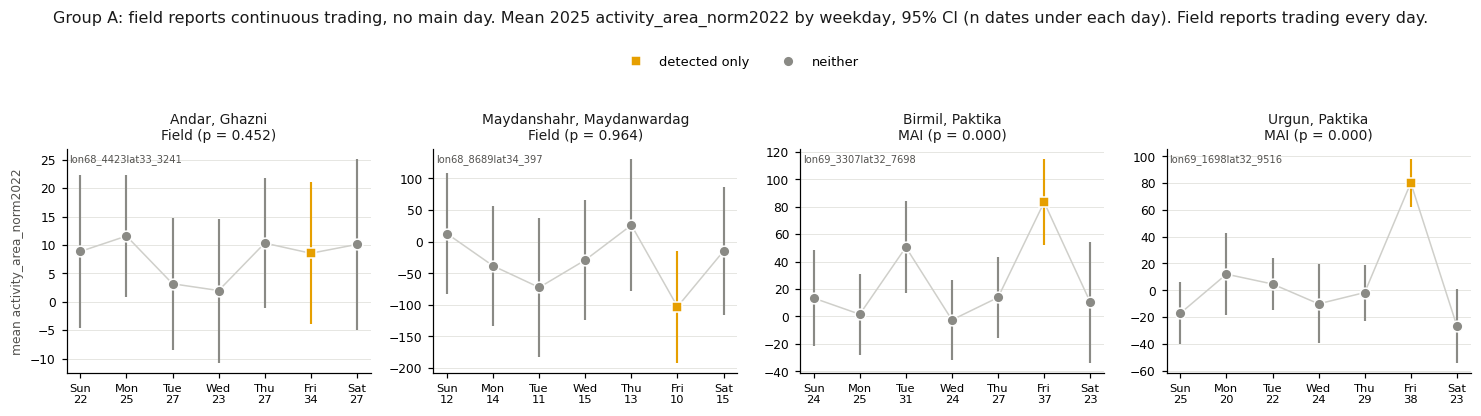

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_A.png


In [318]:
show_main("A")

**Follow-up: do Maydanshahr and Andar show the same activity every day, year by year?**
For each year 2018-2025 (2017 and 2026 are partial years and are left out): Friday vs the other six days (one-tailed Welch) and a Welch one-way ANOVA of equal means across the seven weekdays. `same_every_day` = yes when neither test is significant at 5%.

In [319]:
A_MARKETS = {"Maydanshahr": "lon68_8689lat34_397", "Andar": "lon68_4423lat33_3241"}
FU_A = {}
for name, m in A_MARKETS.items():
    t = by_year(m, {FRI})
    t["same_every_day"] = np.where(t.p_test_gt_other.isna() | t.p_anova_equal_days.isna(), "n/a",
                                   np.where((t.p_test_gt_other >= ALPHA) & (t.p_anova_equal_days >= ALPHA), "yes", "no"))
    FU_A[name] = t
    GROUP_SHEETS["A"][f"Follow-up: {name} by year"] = t
    print(f"{name} ({m}): Friday vs the other six days, by year")
    display(t[BY_YEAR_SHOW + ["same_every_day"]].round(3))

Maydanshahr (lon68_8689lat34_397): Friday vs the other six days, by year


,district,year,test_days,n_test,n_other,mean_test,mean_other,diff,p_test_gt_other,market_like,p_anova_equal_days,weekly_pattern,same_every_day
0,Maydanshahr,2018,Fri,14,87,61.766,0.514,61.252,0.112,no,0.229,no,yes
1,Maydanshahr,2019,Fri,11,34,110.461,16.178,94.284,0.013,yes,0.472,no,no
2,Maydanshahr,2020,Fri,10,39,19.353,-32.024,51.377,0.221,no,0.541,no,yes
3,Maydanshahr,2021,Fri,20,111,22.400,0.028,22.372,0.305,no,0.341,no,yes
4,Maydanshahr,2022,Fri,13,67,46.403,-2.431,48.834,0.166,no,0.830,no,yes
5,Maydanshahr,2023,Fri,9,85,22.747,-19.648,42.395,0.248,no,0.582,no,yes
6,Maydanshahr,2024,Fri,7,70,-71.538,4.251,-75.789,0.923,no,0.003,yes,no
7,Maydanshahr,2025,Fri,10,80,-103.007,-18.790,-84.217,0.964,no,0.433,no,yes


Andar (lon68_4423lat33_3241): Friday vs the other six days, by year


,district,year,test_days,n_test,n_other,mean_test,mean_other,diff,p_test_gt_other,market_like,p_anova_equal_days,weekly_pattern,same_every_day
0,Andar,2018,Fri,40,166,14.898,1.684,13.214,0.027,yes,0.408,no,no
1,Andar,2019,Fri,22,112,45.331,1.423,43.908,0.000,yes,0.000,yes,no
2,Andar,2020,Fri,24,103,85.567,-9.221,94.788,0.000,yes,0.000,yes,no
3,Andar,2021,Fri,47,241,106.890,-0.664,107.554,0.000,yes,0.000,yes,no
4,Andar,2022,Fri,39,189,107.593,-3.108,110.701,0.000,yes,0.000,yes,no
5,Andar,2023,Fri,31,165,83.927,-7.310,91.237,0.000,yes,0.000,yes,no
6,Andar,2024,Fri,28,138,11.443,4.365,7.078,0.186,no,0.959,no,yes
7,Andar,2025,Fri,34,151,8.528,7.717,0.811,0.452,no,0.883,no,yes


**Group A summary**

- **2025:** Birmil (83 vs 16) and Urgun (80 vs -7) have a clear Friday peak (p < 0.001), so both go to the MAI. Andar (p = 0.45) and Maydanshahr (p = 0.96) show no Friday peak, so both go to the field.
- **Maydanshahr coverage:** under half of its 2025 images have a reading on six of the seven weekdays (29% on Fridays), so its test rests on 10 Fridays and 80 other dates.
- **Birmil:** there are readings in every month of 2025. The longest gap is 13 days (15-28 Feb), so the data show no closure of a couple of months.
- **Follow-up, Maydanshahr (2018-2025):** the Friday test finds a Friday peak only in 2019 (p = 0.01). The ANOVA finds a weekly pattern only in 2024, when Friday is lower than the other days. Activity is the same every day in all other years, consistent with the field.
- **Follow-up, Andar (2018-2025):** Friday was a clear market day from 2018 to 2023, with a weekly pattern from 2019 to 2023. Both disappear in 2024 and 2025, when activity is the same every day. Andar looks like a weekly market that moved to continuous trading around 2024, which matches the field report.

## Markets with partially overlapping schedules (21 markets: groups B, C and D)

Every weekday named by either source is tested on its own against the comparison days: the weekdays that
neither source names as an operating day (2025, one-tailed Welch, H1: the day is higher). A day with p < 0.05
shows **distinctive market-day activity**. Days are classed as:

- **overlap:** named by both the algorithm and the field validation
- **ours-only:** detected by the algorithm only
- **field-only:** reported by the field validation only

Where a market has both ours-only and field-only days (group D), the two are also compared directly.

In [320]:
OV_MKTS = MKT.index[MKT.group.isin(["B", "C", "D"])].tolist()
OV_ROLE_ORDER = ["overlap", "ours-only", "field-only"]
OV = day_tests(OV_MKTS)
OV_COUNTS = day_counts(OV, OV_ROLE_ORDER)
print(f"{len(OV_MKTS)} markets with partially overlapping schedules; days with distinctive market-day "
      f"activity in {YEAR} (vs the days neither source names):")
display(OV_COUNTS)
for role in OV_ROLE_ORDER:
    print(f"\n{role} days with distinctive activity: {list_days(OV, role)}")
    print(f"{role} days without data: {list_days(OV, role, 'no data')}")
GROUP_SHEETS["Overlap B-D"]["Day-level tests, 2025 (each day vs the days neither source names)"] = OV
GROUP_SHEETS["Overlap B-D"]["Counts by role, 2025"] = OV_COUNTS.reset_index()
display(OV[["group", "district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day",
            "mean_comparison", "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))

21 markets with partially overlapping schedules; days with distinctive market-day activity in 2025 (vs the days neither source names):


distinctive,yes,no,no data,days,markets,markets_with_a_distinctive_day
role,,,,,,
overlap,21,1,0,22,21,20
ours-only,7,1,0,8,8,7
field-only,5,14,0,19,17,5



overlap days with distinctive activity: Nad-e-Ali Fri (lon64_0787lat31_5441); Nad-e-Ali Thu (lon64_2982lat31_7762); Nad-e-Ali Fri (lon64_359lat31_7969); Ghormach Wed (lon63_7803lat35_731); Ghormach Sat (lon63_7803lat35_731); Nahr-e-Saraj Sat (lon64_4657lat31_7671); Washer Wed (lon64_2906lat32_1391); Washer Tue (lon64_3886lat32_1787); Chahab Fri (lon69_8014lat37_2963); Qades Tue (lon63_6691lat35_0506); Almar Mon (lon64_281lat35_92); Almar Sat (lon64_5358lat35_8487); Alishang Wed (lon70_117lat34_8975); Batikot Thu (lon70_7449lat34_2702); Muhmanddara Sat (lon70_9089lat34_2412); Shenwar Fri (lon70_8026lat34_1925); Chaparhar Mon (lon70_3611lat34_2786); Nahr-e-Saraj Wed (lon64_4065lat31_7988); Nahr-e-Saraj Tue (lon64_7449lat31_8847); Khwajabahawuddin Sat (lon69_5419lat37_338); Murghab Sat (lon63_3293lat35_5834)
overlap days without data: none

ours-only days with distinctive activity: Nad-e-Ali Tue (lon64_2982lat31_7762); Nad-e-Ali Mon (lon64_359lat31_7969); Ghormach Tue (lon63_7803lat35_73

,group,district,mktID,role,day,n_day,n_comparison,mean_day,mean_comparison,diff,p_one_tailed,distinctive,low_power
0,B,Nad-e-Ali,lon64_0787lat31_5441,overlap,Fri,34,118,44.953,12.898,32.055,0.008,yes,0
1,B,Nad-e-Ali,lon64_0787lat31_5441,ours-only,Tue,39,118,19.181,12.898,6.283,0.307,no,0
2,B,Nad-e-Ali,lon64_2982lat31_7762,overlap,Thu,31,99,69.334,1.831,67.503,0.000,yes,0
3,B,Nad-e-Ali,lon64_2982lat31_7762,ours-only,Tue,37,99,72.681,1.831,70.850,0.000,yes,0
4,B,Nad-e-Ali,lon64_359lat31_7969,overlap,Fri,34,114,91.408,3.460,87.948,0.000,yes,0
5,B,Nad-e-Ali,lon64_359lat31_7969,ours-only,Mon,29,114,81.041,3.460,77.581,0.000,yes,0
6,B,Ghormach,lon63_7803lat35_731,overlap,Wed,26,119,38.972,6.045,32.927,0.000,yes,0
7,B,Ghormach,lon63_7803lat35_731,overlap,Sat,26,119,40.129,6.045,34.084,0.000,yes,0
8,B,Ghormach,lon63_7803lat35_731,ours-only,Tue,20,119,106.578,6.045,100.533,0.000,yes,0
9,C,Nahr-e-Saraj,lon64_4657lat31_7671,overlap,Sat,37,112,80.865,-0.921,81.786,0.000,yes,0


In [321]:
# Disputed days compared directly: ours-only vs field-only (markets that have both)
OV_DIRECT = direct(OV_MKTS, "ours-only", "field-only")
GROUP_SHEETS["Overlap B-D"]["Direct comparison, ours-only vs field-only days, 2025"] = OV_DIRECT
print(f"{len(OV_DIRECT)} markets have both ours-only and field-only days:")
display(OV_DIRECT.round(3))

4 markets have both ours-only and field-only days:


,group,province,district,mktID,ours_only_days,n_ours_only,mean_ours_only,field_only_days,n_field_only,mean_field_only,diff,p_ours_only_gt_field_only,p_field_only_gt_ours_only,higher
0,D,Hilmand,Nahr-e-Saraj,lon64_4065lat31_7988,Sun,24,73.663,Thu,21,16.339,57.324,0.000,1.000,ours_only
1,D,Hilmand,Nahr-e-Saraj,lon64_7449lat31_8847,Sat,32,85.381,Mon,20,7.722,77.659,0.000,1.000,ours_only
2,D,Takhar,Khwajabahawuddin,lon69_5419lat37_338,Wed,28,-16.687,Fri,23,-64.345,47.659,0.024,0.976,ours_only
3,D,Badghis,Murghab,lon63_3293lat35_5834,Mon,36,46.041,Wed,21,-12.775,58.816,0.000,1.000,ours_only


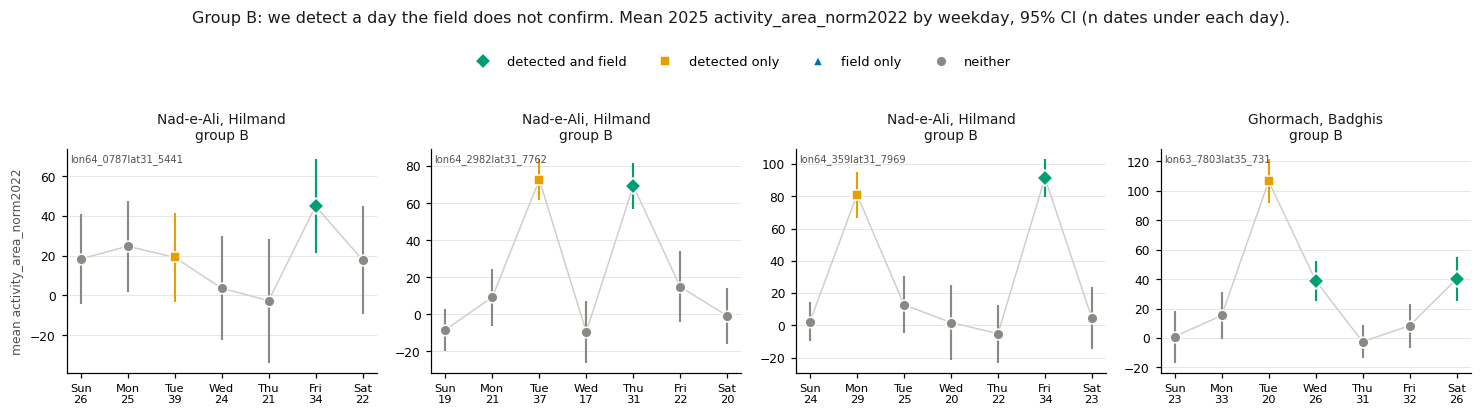

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_B.png


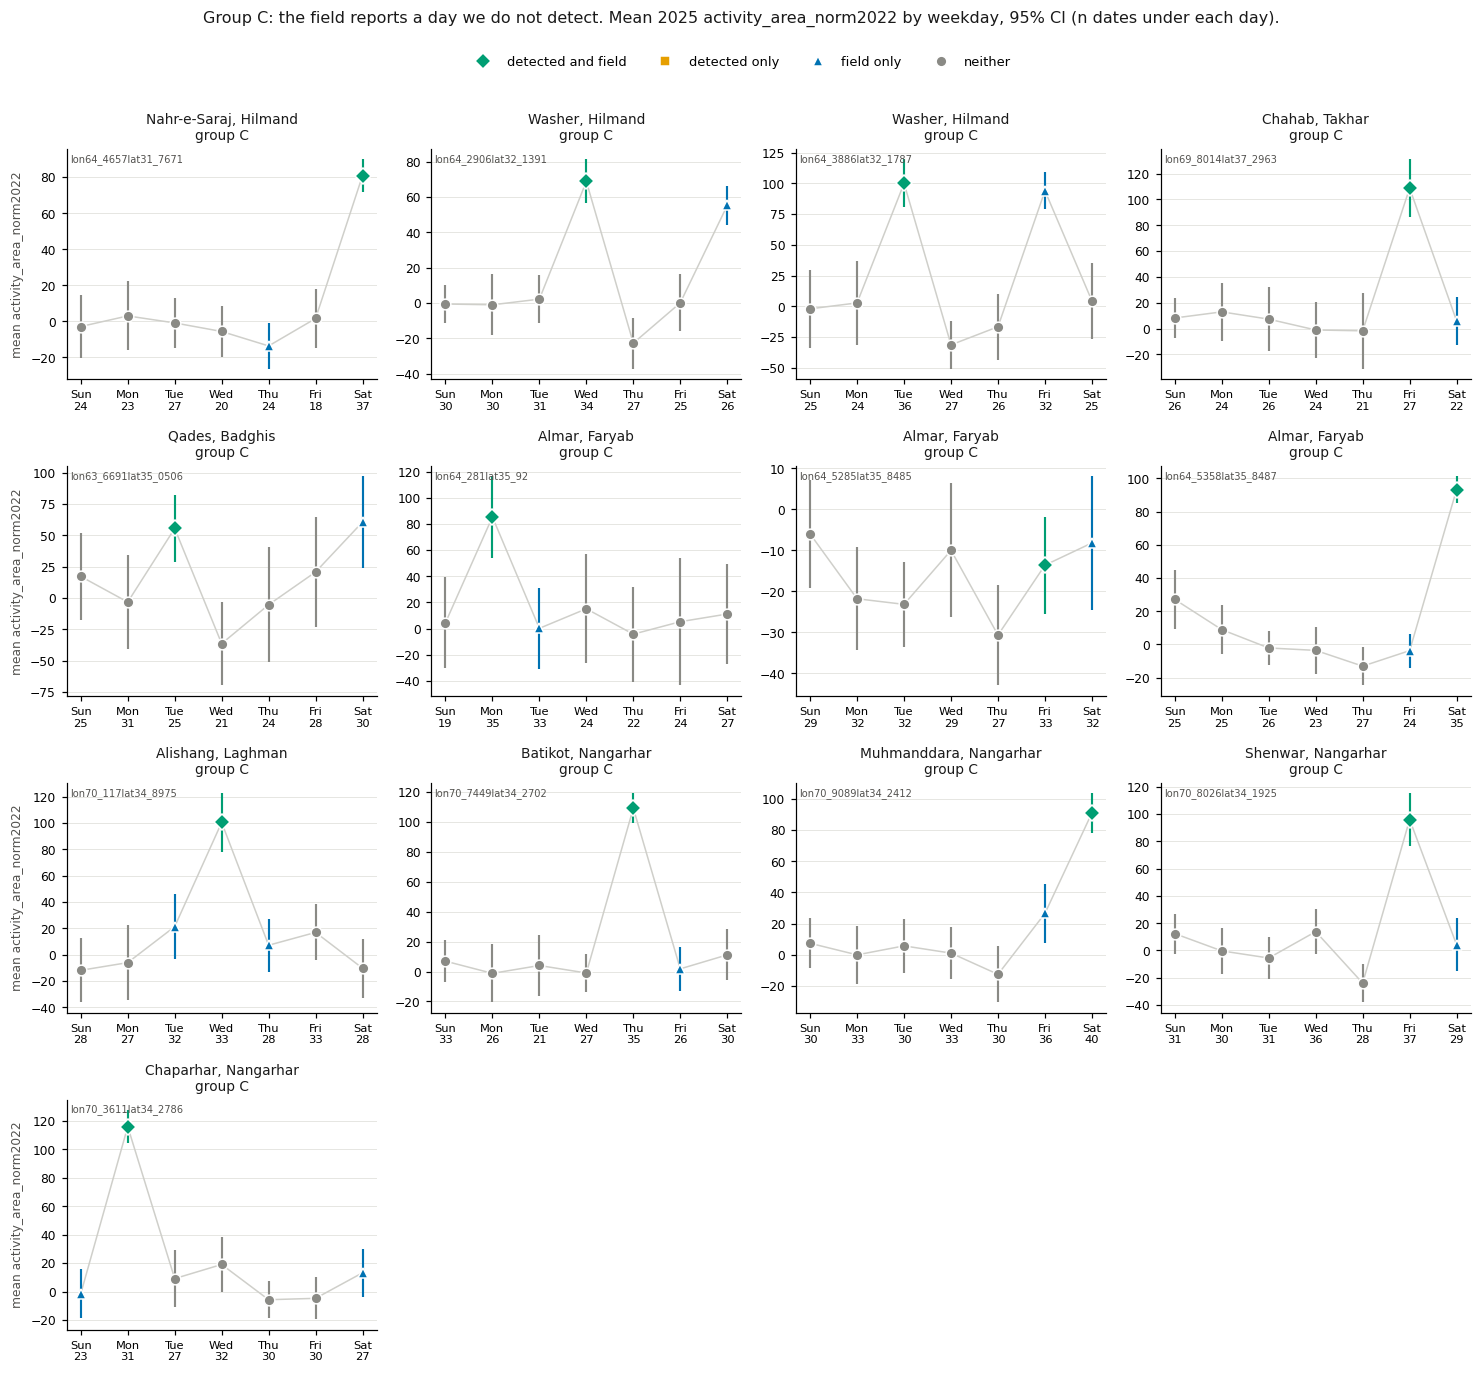

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_C.png


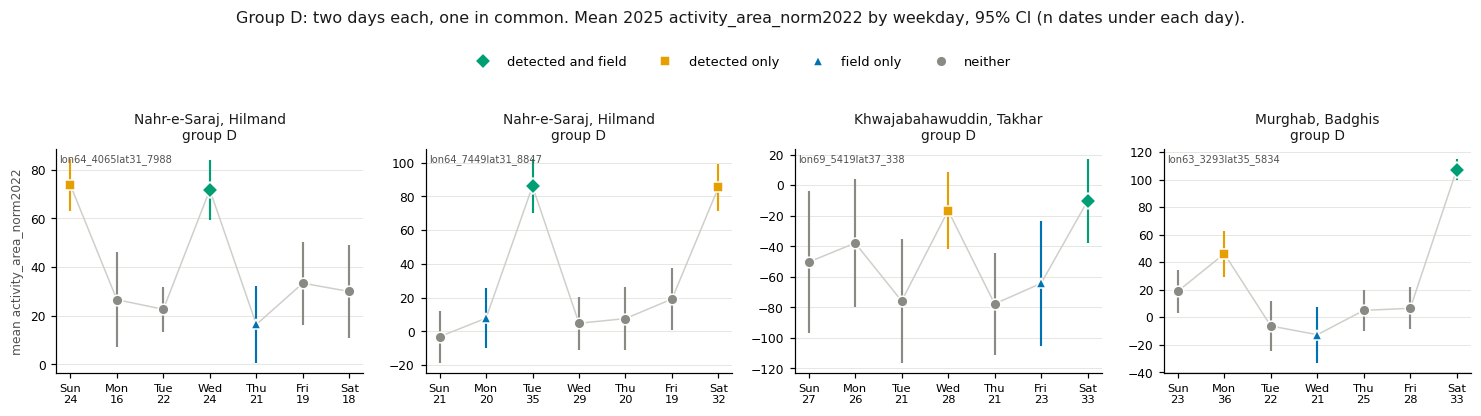

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_D.png


In [322]:
for g in ["B", "C", "D"]:
    plot_markets(MKT.index[MKT.group == g].tolist(), f"Group {g}: {GROUP_TITLE[g]}",
                 f"weekday_profile_{ACTIVITY_VAR}_group_{g}.png")

**Timing (2018-2025, 2017 and 2026 are partial years):** each day is tested year by year against the same
comparison days.

- **Field-only days with distinctive activity in 2025:** the first year they show market-day activity
  (`first_year_market_like`), and the start of the unbroken run up to 2025 (`market_like_since`).
- **Ours-only days with distinctive activity in 2025:** the last year they did not show market-day activity
  (`last_year_not_market_like`), and `market_like_since`.
- **Ours-only days without distinctive activity in 2025:** the last year they did show it (`last_year_market_like`).

In [323]:
OV_FIELD_T, OV_FIELD_Y = timing(OV[(OV.role == "field-only") & (OV.distinctive == "yes")])
OV_OURS_T, OV_OURS_Y = timing(OV[(OV.role == "ours-only") & (OV.distinctive == "yes")])
OV_OURS_NO_T, OV_OURS_NO_Y = timing(OV[(OV.role == "ours-only") & (OV.distinctive == "no")])
for title, t, y, cols in [
        ("Field-only days with distinctive activity in 2025: first year of market-day activity",
         OV_FIELD_T, OV_FIELD_Y, ["first_year_market_like", "market_like_since"]),
        ("Ours-only days with distinctive activity in 2025: last year without market-day activity",
         OV_OURS_T, OV_OURS_Y, ["last_year_not_market_like", "market_like_since"]),
        ("Ours-only days without distinctive activity in 2025: last year with market-day activity",
         OV_OURS_NO_T, OV_OURS_NO_Y, ["last_year_market_like"])]:
    print(f"\n{title} ({len(t)} days)")
    if len(t):
        display(t[["group", "district", "mktID", "day", "years_market_like"] + cols])
        GROUP_SHEETS["Overlap B-D"][title] = t
        GROUP_SHEETS["Overlap B-D"][title.split(":")[0] + ", by year"] = y


Field-only days with distinctive activity in 2025: first year of market-day activity (5 days)


,group,district,mktID,day,years_market_like,first_year_market_like,market_like_since
0,C,Washer,lon64_2906lat32_1391,Sat,"2019, 2020, 2021, 2022, 2024, 2025",2019,2024
1,C,Washer,lon64_3886lat32_1787,Fri,"2018, 2019, 2020, 2021, 2022, 2024, 2025",2018,2024
2,C,Qades,lon63_6691lat35_0506,Sat,"2018, 2019, 2020, 2021, 2023, 2024, 2025",2018,2023
3,C,Alishang,lon70_117lat34_8975,Tue,2025,2025,2025
4,C,Muhmanddara,lon70_9089lat34_2412,Fri,2025,2025,2025



Ours-only days with distinctive activity in 2025: last year without market-day activity (7 days)


,group,district,mktID,day,years_market_like,last_year_not_market_like,market_like_since
0,B,Nad-e-Ali,lon64_2982lat31_7762,Tue,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
1,B,Nad-e-Ali,lon64_359lat31_7969,Mon,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
2,B,Ghormach,lon63_7803lat35_731,Tue,"2020, 2021, 2022, 2023, 2024, 2025",2019,2020
3,D,Nahr-e-Saraj,lon64_4065lat31_7988,Sun,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
4,D,Nahr-e-Saraj,lon64_7449lat31_8847,Sat,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
5,D,Khwajabahawuddin,lon69_5419lat37_338,Wed,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
6,D,Murghab,lon63_3293lat35_5834,Mon,"2020, 2021, 2022, 2023, 2024, 2025",2019,2020



Ours-only days without distinctive activity in 2025: last year with market-day activity (1 days)


,group,district,mktID,day,years_market_like,last_year_market_like
0,B,Nad-e-Ali,lon64_0787lat31_5441,Tue,"2018, 2019, 2020, 2021, 2022",2022


**Summary: partially overlapping schedules**

The 21 markets name 49 operating weekdays between them: 22 named by both sources, 8 by the algorithm only and 19 by the field validation only. Each is compared with the weekdays that neither source names.

| Days | Total | Distinctive market-day activity in 2025 | Markets with such a day |
|---|---|---|---|
| Overlap (both sources) | 22 | **21** (1 not) | 20 of 21 |
| Ours-only (algorithm only) | 8 | **7** (1 not) | 7 of 8 |
| Field-only (field only) | 19 | **5** (14 not) | 5 of 17 |

- **Overlap days:** 21 of 22 show distinctive activity. The exception is Almar lon64_5285 Fri (p = 0.24).
- **Ours-only days:** 7 of 8 show distinctive activity: Ghormach Tue, Nad-e-Ali lon64_2982 Tue, Nad-e-Ali lon64_359 Mon, Nahr-e-Saraj lon64_4065 Sun, Nahr-e-Saraj lon64_7449 Sat, Khwajabahawuddin Wed and Murghab Mon. Not distinctive: Nad-e-Ali lon64_0787 Tue (p = 0.31).
- **Field-only days:** 5 of 19 show distinctive activity: Qades Sat, Washer lon64_2906 Sat, Washer lon64_3886 Fri, Alishang Tue (p = 0.047) and Muhmanddara Fri. Alishang's other field-only day, Thu, does not.
- **Direct comparison (the 4 group D markets):** the ours-only day is higher than the field-only day in all four: both Nahr-e-Saraj markets and Murghab (p < 0.001), and Khwajabahawuddin (p = 0.02).

**Timing (2018-2025)**

- **Field-only days with distinctive activity in 2025, first year of market-day activity:**
  - Qades Sat: 2018, in every year since except 2022.
  - Washer lon64_3886 Fri: 2018, in every year since except 2023.
  - Washer lon64_2906 Sat: 2019, in every year since except 2023.
  - Alishang Tue and Muhmanddara Fri: 2025, the only year with market-day activity.
- **Ours-only days with distinctive activity in 2025:** five of the seven show market-day activity in every year from 2018 to 2025, so there is no year in which they stopped. Ghormach Tue and Murghab Mon last lacked it in 2019 and have shown it every year since 2020.
- **Ours-only days without distinctive activity in 2025, last year of market-day activity:** Nad-e-Ali lon64_0787 Tue in 2022 (it had activity every year from 2018 to 2022).

## Markets with no overlapping operating day (13 markets: group E)

Each predicted day and each field day is tested on its own against the comparison days: the weekdays that
neither source names (so a predicted day is never compared with a field day here). One-tailed Welch, H1: the
day is higher; p < 0.05 = activity above the non-market days. The predicted and field days are also compared
directly.

In [324]:
E_MKTS = MKT.index[MKT.group == "E"].tolist()
E_LABELS = {"ours-only": "predicted", "field-only": "field"}
E_ROLE_ORDER = ["predicted", "field"]
ED = day_tests(E_MKTS, E_LABELS)
E_COUNTS = day_counts(ED, E_ROLE_ORDER)
print(f"{len(E_MKTS)} markets with no overlapping day; days with activity above the non-market days in {YEAR}:")
display(E_COUNTS)
for role in E_ROLE_ORDER:
    print(f"\n{role} days above the non-market days: {list_days(ED, role)}")
    print(f"{role} days without data: {list_days(ED, role, 'no data')}")
GROUP_SHEETS["No overlap E"]["Day-level tests, 2025 (each day vs the days neither source names)"] = ED
GROUP_SHEETS["No overlap E"]["Counts by role, 2025"] = E_COUNTS.reset_index()
display(ED[["district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day", "mean_comparison",
            "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))

13 markets with no overlapping day; days with activity above the non-market days in 2025:


distinctive,yes,no,no data,days,markets,markets_with_a_distinctive_day
role,,,,,,
predicted,13,4,0,17,13,10
field,2,15,0,17,13,2



predicted days above the non-market days: Baghran Tue (lon64_9554lat32_6721); Lashkargah Fri (lon64_3867lat31_7137); Nad-e-Ali Mon (lon64_2347lat31_532); Reg (Khanneshin) Thu (lon63_976lat30_6037); Sangin Wed (lon64_9918lat32_2028); Sangin Sat (lon64_9918lat32_2028); Washer Sun (lon64_2259lat32_1869); Maywand Sun (lon64_8492lat31_9068); Maywand Wed (lon64_8492lat31_9068); Shiberghan Sun (lon65_7314lat36_6728); Shiberghan Wed (lon65_7314lat36_6728); Sozmaqala Sat (lon66_1813lat35_914); Khogyani Thu (lon70_059lat34_2793)
predicted days without data: none

field days above the non-market days: Nawzad Thu (lon64_5537lat32_1786); Bakwa Sat (lon63_1157lat32_2064)
field days without data: none


,district,mktID,role,day,n_day,n_comparison,mean_day,mean_comparison,diff,p_one_tailed,distinctive,low_power
0,Baghran,lon64_9554lat32_6721,predicted,Tue,29,128,39.370,4.711,34.659,0.000,yes,0
1,Baghran,lon64_9554lat32_6721,field,Mon,18,128,7.237,4.711,2.526,0.382,no,0
2,Kajaki,lon65_0457lat32_3879,predicted,Sun,26,60,31.652,42.165,-10.513,0.759,no,0
3,Kajaki,lon65_0457lat32_3879,predicted,Wed,29,60,41.104,42.165,-1.061,0.537,no,0
4,Kajaki,lon65_0457lat32_3879,field,Mon,23,60,54.867,42.165,12.702,0.237,no,0
5,Kajaki,lon65_0457lat32_3879,field,Thu,23,60,22.331,42.165,-19.834,0.870,no,0
6,Lashkargah,lon64_3867lat31_7137,predicted,Fri,32,126,87.283,9.228,78.054,0.000,yes,0
7,Lashkargah,lon64_3867lat31_7137,field,Wed,21,126,4.452,9.228,-4.776,0.719,no,0
8,Nad-e-Ali,lon64_2347lat31_532,predicted,Mon,32,125,87.036,-1.850,88.886,0.000,yes,0
9,Nad-e-Ali,lon64_2347lat31_532,field,Sat,28,125,8.434,-1.850,10.284,0.130,no,0


,group,province,district,mktID,predicted_days,n_predicted,mean_predicted,field_days,n_field,mean_field,diff,p_predicted_gt_field,p_field_gt_predicted,higher
0,E,Hilmand,Baghran,lon64_9554lat32_6721,Tue,29,39.370,Mon,18,7.237,32.133,0.002,0.998,predicted
1,E,Hilmand,Kajaki,lon65_0457lat32_3879,Sun+Wed,55,36.636,Mon+Thu,46,38.599,-1.963,0.555,0.445,neither
2,E,Hilmand,Lashkargah,lon64_3867lat31_7137,Fri,32,87.283,Wed,21,4.452,82.831,0.000,1.000,predicted
3,E,Hilmand,Nad-e-Ali,lon64_2347lat31_532,Mon,32,87.036,Sat,28,8.434,78.602,0.000,1.000,predicted
4,E,Hilmand,Nawzad,lon64_5537lat32_1786,Sat,39,-0.756,Thu,22,68.525,-69.281,1.000,0.000,field
5,E,Hilmand,Reg (Khanneshin),lon63_976lat30_6037,Thu,30,22.810,Tue,30,-0.546,23.356,0.005,0.995,predicted
6,E,Hilmand,Sangin,lon64_9918lat32_2028,Wed+Sat,62,93.105,Fri,23,-9.826,102.931,0.000,1.000,predicted
7,E,Hilmand,Washer,lon64_2259lat32_1869,Sun,37,82.702,Thu,29,-8.133,90.835,0.000,1.000,predicted
8,E,Kandahar,Maywand,lon64_8492lat31_9068,Sun+Wed,61,47.586,Fri,20,4.376,43.211,0.000,1.000,predicted
9,E,Farah,Bakwa,lon63_1157lat32_2064,Fri,36,-8.446,Sat,25,62.005,-70.451,1.000,0.000,field


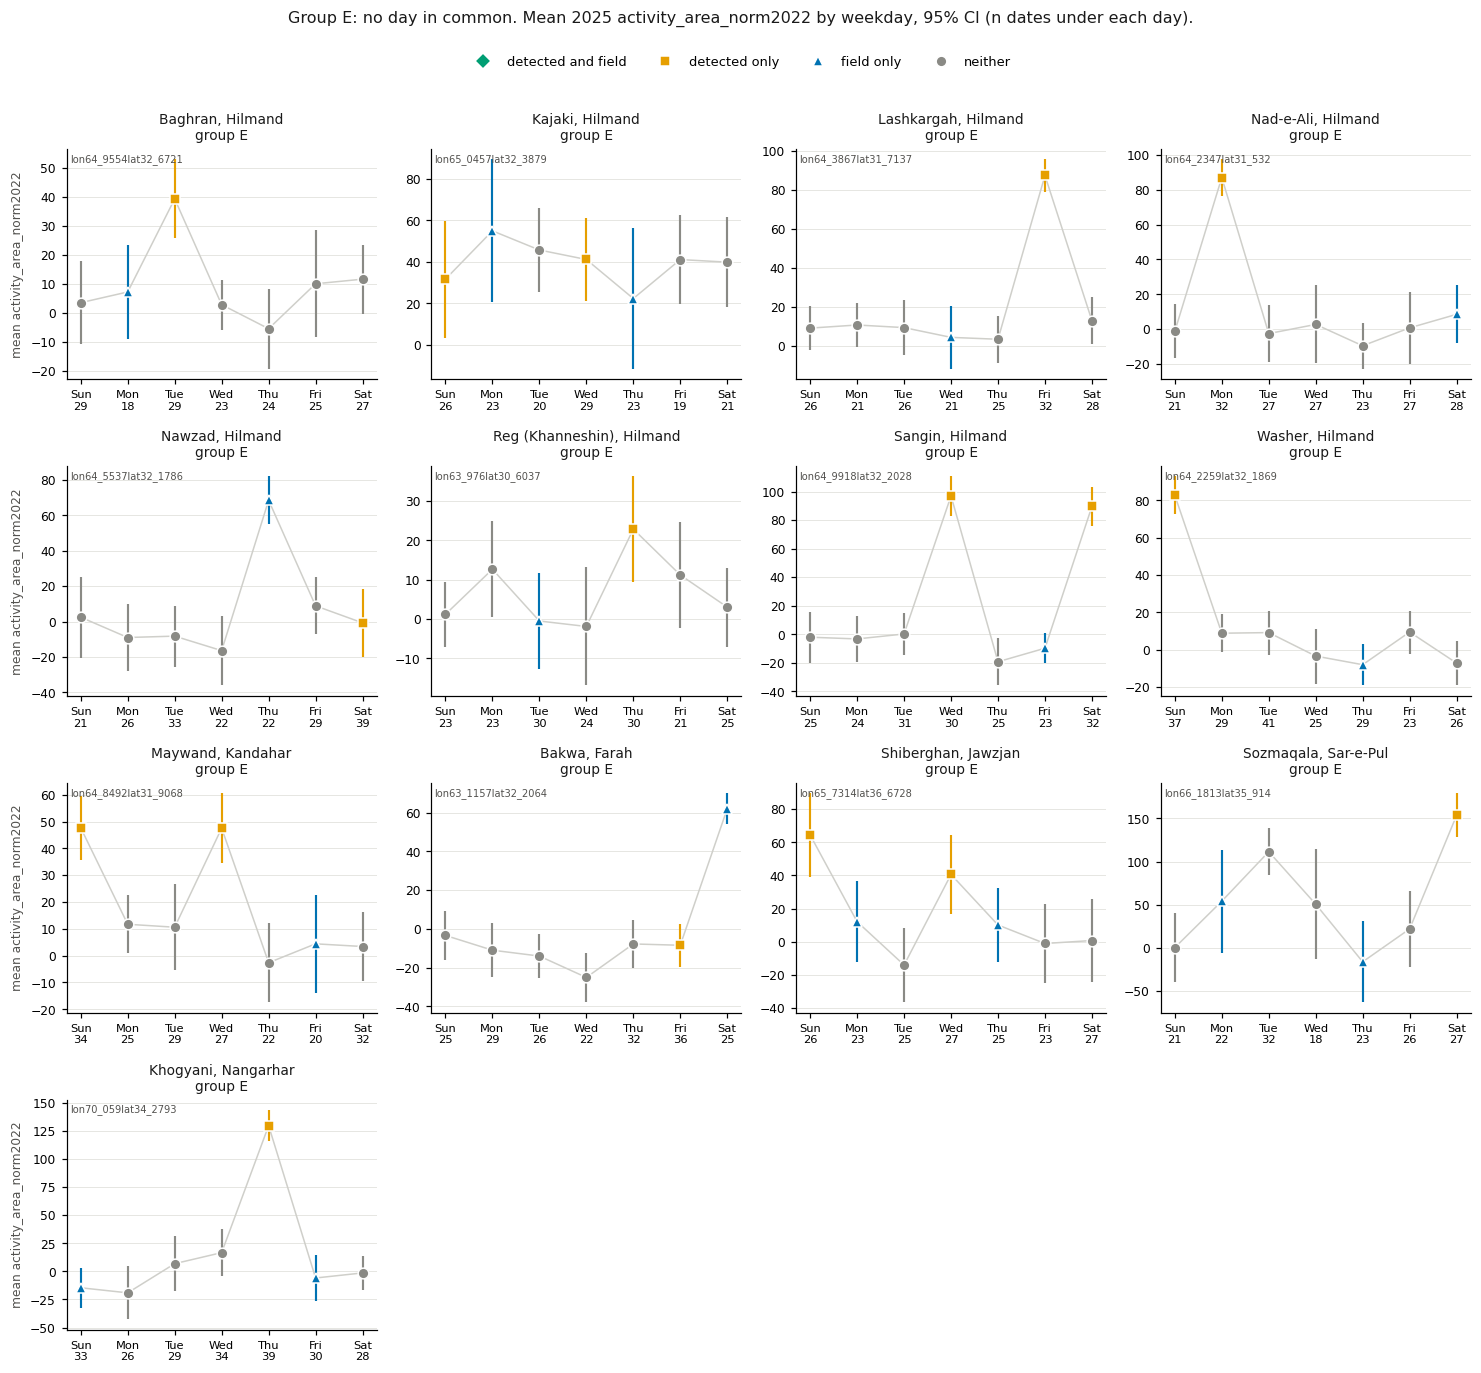

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_E.png


In [325]:
# Predicted days vs field days, compared directly (pooled within each source)
E_DIRECT = direct(E_MKTS, "ours-only", "field-only", E_LABELS)
GROUP_SHEETS["No overlap E"]["Direct comparison, predicted vs field days, 2025"] = E_DIRECT
display(E_DIRECT.round(3))
plot_markets(E_MKTS, f"Group E: {GROUP_TITLE['E']}", f"weekday_profile_{ACTIVITY_VAR}_group_E.png")

**Timing (2018-2025):** for the days that are above the non-market days in 2025, tested year by year
against the same comparison days.

- **Predicted days:** the last year they stopped showing activity above the non-market days
  (`last_year_not_market_like`), and the start of the unbroken run up to 2025 (`market_like_since`).
- **Field days:** the first year they started showing it (`first_year_market_like`), and `market_like_since`.
- **Predicted days not above the non-market days in 2025:** the last year they were (`last_year_market_like`).

In [326]:
E_PRED_T, E_PRED_Y = timing(ED[(ED.role == "predicted") & (ED.distinctive == "yes")])
E_FIELD_T, E_FIELD_Y = timing(ED[(ED.role == "field") & (ED.distinctive == "yes")])
E_PRED_NO_T, E_PRED_NO_Y = timing(ED[(ED.role == "predicted") & (ED.distinctive == "no")])
for title, t, y, cols in [
        ("Predicted days above the non-market days in 2025: last year they stopped",
         E_PRED_T, E_PRED_Y, ["last_year_not_market_like", "market_like_since"]),
        ("Field days above the non-market days in 2025: first year they started",
         E_FIELD_T, E_FIELD_Y, ["first_year_market_like", "market_like_since"]),
        ("Predicted days not above the non-market days in 2025: last year they were",
         E_PRED_NO_T, E_PRED_NO_Y, ["last_year_market_like"])]:
    print(f"\n{title} ({len(t)} days)")
    if len(t):
        display(t[["district", "mktID", "day", "years_market_like"] + cols])
        GROUP_SHEETS["No overlap E"][title] = t
        GROUP_SHEETS["No overlap E"][title.split(":")[0] + ", by year"] = y


Predicted days above the non-market days in 2025: last year they stopped (13 days)


,district,mktID,day,years_market_like,last_year_not_market_like,market_like_since
0,Baghran,lon64_9554lat32_6721,Tue,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
1,Lashkargah,lon64_3867lat31_7137,Fri,"2019, 2020, 2021, 2022, 2023, 2024, 2025",2018,2019
2,Nad-e-Ali,lon64_2347lat31_532,Mon,"2018, 2021, 2022, 2023, 2024, 2025",2020,2021
3,Reg (Khanneshin),lon63_976lat30_6037,Thu,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
4,Sangin,lon64_9918lat32_2028,Wed,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
5,Sangin,lon64_9918lat32_2028,Sat,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
6,Washer,lon64_2259lat32_1869,Sun,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
7,Maywand,lon64_8492lat31_9068,Sun,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
8,Maywand,lon64_8492lat31_9068,Wed,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018
9,Shiberghan,lon65_7314lat36_6728,Sun,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",<NA>,2018



Field days above the non-market days in 2025: first year they started (2 days)


,district,mktID,day,years_market_like,first_year_market_like,market_like_since
0,Nawzad,lon64_5537lat32_1786,Thu,"2023, 2024, 2025",2023,2023
1,Bakwa,lon63_1157lat32_2064,Sat,"2023, 2024, 2025",2023,2023



Predicted days not above the non-market days in 2025: last year they were (4 days)


,district,mktID,day,years_market_like,last_year_market_like
0,Kajaki,lon65_0457lat32_3879,Sun,"2018, 2019, 2020, 2021, 2022, 2023",2023
1,Kajaki,lon65_0457lat32_3879,Wed,"2018, 2019, 2020, 2021, 2022, 2023",2023
2,Nawzad,lon64_5537lat32_1786,Sat,"2018, 2019, 2020, 2021, 2022",2022
3,Bakwa,lon63_1157lat32_2064,Fri,"2018, 2019, 2020, 2021, 2022, 2023",2023


**Summary: no overlapping day**

The 13 markets have 17 predicted days and 17 field days. Each is compared with the weekdays that neither source names. Rodat left this group when its field day was corrected to Tue, an exact match.

| Days | Total | Above the non-market days in 2025 | Markets with such a day |
|---|---|---|---|
| Predicted (algorithm) | 17 | **13** | 10 of 13 |
| Field validation | 17 | **2** | 2 of 13 |

- **Predicted days not above the non-market days:** Kajaki Sun and Wed, Nawzad Sat and Bakwa Fri.
- **Field days above the non-market days:** Nawzad Thu and Bakwa Sat.
- **Direct comparison:** the predicted days are higher than the field days in 10 markets (p <= 0.005), and the field days are higher in Bakwa and Nawzad (p < 0.001). Kajaki shows no difference (p = 0.45) and no weekly pattern at all.

**Timing (2018-2025)**

- **Predicted days above the non-market days in 2025, last year they stopped:**
  - 9 of the 13 days were above the non-market days in every year from 2018 to 2025, so they never stopped: Baghran Tue, Reg Thu, Sangin Wed and Sat, Washer Sun, Maywand Sun and Wed, Shiberghan Sun and Khogyani Thu.
  - The other four last stopped in:
    - Lashkargah Fri: 2018 (above every year since 2019).
    - Nad-e-Ali lon64_2347 Mon: 2020 (above in 2018 and every year since 2021).
    - Shiberghan Wed: 2024 (above every other year).
    - Sozmaqala Sat: 2024 (above in 2018-2023 and 2025).
- **Field days above the non-market days in 2025, first year they started:** Bakwa Sat and Nawzad Thu both started in **2023** and have been above every year since.
- **The predicted days that are no longer above the non-market days:** they were last above in Nawzad Sat in 2022, in Bakwa Fri in 2023, and in Kajaki Sun and Wed in 2023. So Nawzad's market day seems to have moved from Saturday to Thursday in 2023, and Bakwa's from Friday to Saturday around 2023. Kajaki's predicted days have shown no signal since 2024.

## Group F: no field-validated market day (5 markets)

**Main test (2025):** the detected day vs all other weekdays pooled. H1: detected > others. p < 0.05: MAI
(weekly peak on the detected day); otherwise field (no peak, consistent with no trading day).

- Three markets are in the WFP list with no trading day reported: the two Maywand locations ("no bazaar at
  the stated location") and Mahmud-e-Raqi. Nijrab left this group when the field reported its Friday
  livestock trading, an exact match with the MAI day.
- Two Baghlan markets (lon68_7092lat35_9503, lon69_5107lat35_9643) are not in the WFP list, so there is no
  field information on them at all.

**Follow-up by year (2018-2025):** the same test each year, giving the years with a peak on the detected day.

,district,mktID,primary_set1,primary_set2,n1,n2,mean1,mean2,ratio,p_one_tailed,assigned_to,low_power,low_coverage
0,(not in WFP list),lon68_7092lat35_9503,detected: Fri,other days: Sun+Mon+Tue+Wed+Thu+Sat,8,62,79.567,-10.898,NaN,NaN,Neither,0,1
1,(not in WFP list),lon69_5107lat35_9643,detected: Mon,other days: Sun+Tue+Wed+Thu+Fri+Sat,12,79,141.971,-6.914,NaN,0.0,MAI,0,0
2,Maywand,lon64_7811lat31_6409,detected: Thu,other days: Sun+Mon+Tue+Wed+Fri+Sat,34,157,69.699,4.113,16.948,0.0,MAI,0,0
3,Maywand,lon64_8951lat31_546,detected: Sun,other days: Mon+Tue+Wed+Thu+Fri+Sat,33,166,76.704,-2.520,NaN,0.0,MAI,0,0
4,Mahmud-e-Raqi,lon69_3316lat35_0459,detected: Sat,other days: Sun+Mon+Tue+Wed+Thu+Fri,36,170,107.028,7.409,14.445,0.0,MAI,0,0


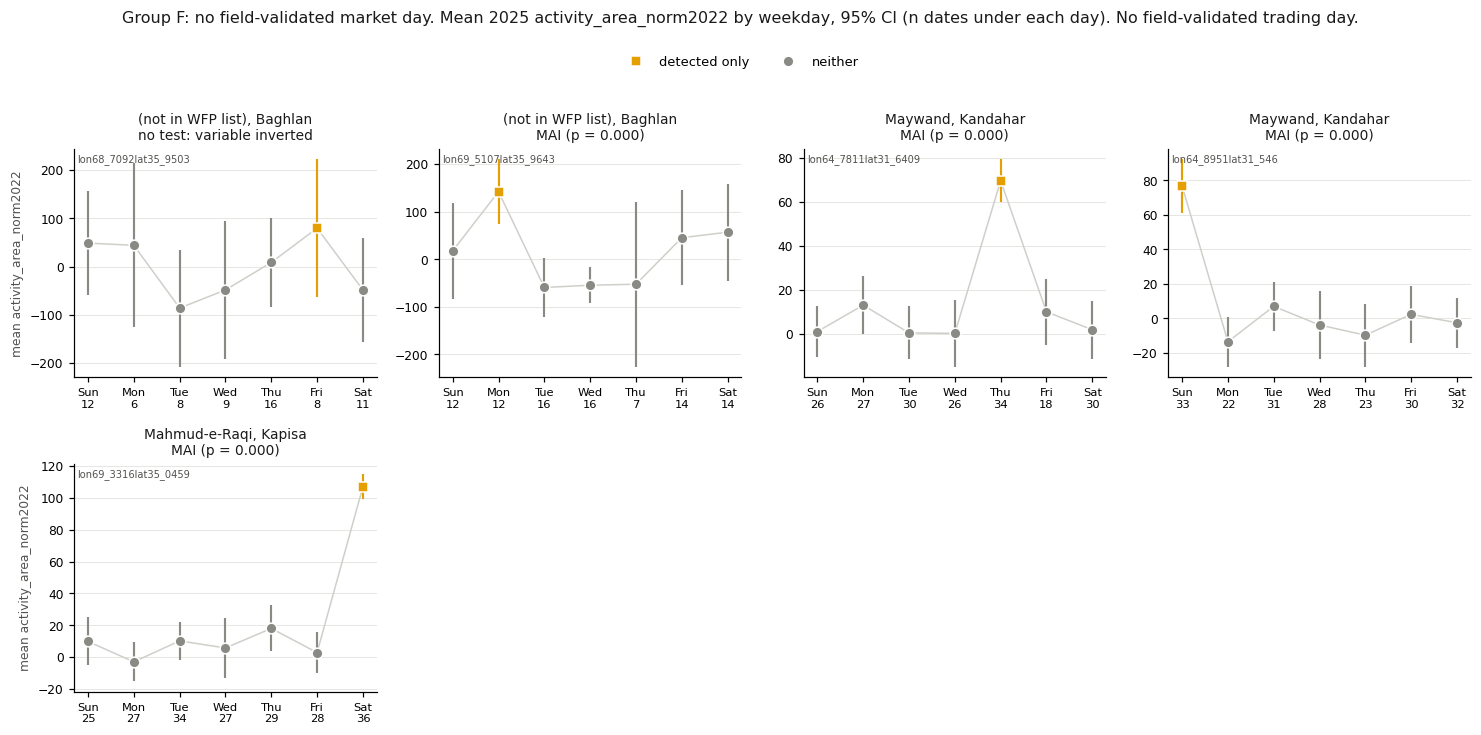

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\weekday_profile_activity_area_norm2022_group_F.png
Detected day vs the other weekdays, by year (2018-2025)


,district,mktID,detected_days,peak_2025,years_with_peak,first_year_with_peak,last_year_with_peak
0,Maywand,lon64_7811lat31_6409,Thu,True,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",2018,2025
1,Maywand,lon64_8951lat31_546,Sun,True,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",2018,2025
2,Mahmud-e-Raqi,lon69_3316lat35_0459,Sat,True,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",2018,2025
3,(not in WFP list),lon69_5107lat35_9643,Mon,True,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025",2018,2025


In [327]:
show_main("F")

FU_F = []
for m, r in MKT[MKT.group == "F"].iterrows():
    if m in SIGN_FLIP:
        continue                                   # not tested: variable runs opposite to raw activity
    t = by_year(m, r.detected)
    GROUP_SHEETS["F"][f"Follow-up by year: {m}"] = t
    yes = t.loc[t.market_like == "yes", "year"].tolist()
    FU_F.append({"district": r.district, "mktID": m, "detected_days": day_label(r.detected),
                 "peak_2025": RES.loc[RES.mktID == m, "assigned_to"].iloc[0] == "MAI",
                 "years_with_peak": ", ".join(map(str, yes)) or "none",
                 "first_year_with_peak": min(yes) if yes else np.nan,
                 "last_year_with_peak": max(yes) if yes else np.nan})
FU_F = pd.DataFrame(FU_F)
GROUP_SHEETS["F"]["Follow-up by year, summary"] = FU_F
print("Detected day vs the other weekdays, by year (2018-2025)")
display(FU_F)

**Group F summary**

- **2025:** all four testable markets show a clear weekly peak on the detected day (p < 0.001), so all four go to the MAI:
  - Maywand lon64_7811 Thu and lon64_8951 Sun: the field found "no bazaar at the stated location".
  - Mahmud-e-Raqi Sat.
  - Baghlan lon69_5107 Mon: not in the WFP list. The peak rests on only 12 Mondays.
- **Not tested:** Baghlan lon68_7092. In this market `activity_area_norm2022` is perfectly negatively correlated with raw activity, so a one-tailed test would point the wrong way. It counts as insufficient data in the summary table.
- **Follow-up by year:** each of the four shows a peak on the detected day in every year from 2018 to 2025, so the satellite signal shows no closure. Field visits that found no bazaar may have gone to the wrong spot, or the activity may not be a market.

## Timing of weekday activity signals

Changes in market schedules could explain part of the disagreement between the two sources. The annual
tests (2018-2025, one-tailed Welch, a signal is p < 0.05) date the signals for two sets of days:

- **Panel A, last year with a signal:** our predicted market days with no market-day signal in 2025.
  - Group A (no main day): the detected Friday, compared with the other six days.
  - Partial and no-match markets: every predicted day, whether the field also names it or not, compared
    with the weekdays neither source names.
- **Panel B, first year with a signal:** field-reported days we do not predict that show a signal in
  2025, compared with the weekdays neither source names. A day first seen in 2018 or 2019, at the start
  of the data, needs two consecutive years with a signal and is dated to the second of them.

Days with no 2025 readings (Murghab Sat) are left out because their 2025 signal cannot be read.

Panel A, predicted days with no signal in 2025: 8 days across 7 markets
Panel B, field-only days with a signal in 2025: 7 days across 7 markets


,panel,category,group,district,mktID,day,named_by,first_year,year
0,A,"Continuous operating market, no main day",A,Maydanshahr,lon68_8689lat34_397,Fri,MAI,<NA>,2019
1,A,"Continuous operating market, no main day",A,Andar,lon68_4423lat33_3241,Fri,MAI,<NA>,2023
2,A,Partial day overlap,C,Almar,lon64_5285lat35_8485,Fri,both sources,<NA>,2024
3,A,Partial day overlap,B,Nad-e-Ali,lon64_0787lat31_5441,Tue,MAI only,<NA>,2022
4,A,Days do not match,E,Kajaki,lon65_0457lat32_3879,Sun,MAI,<NA>,2023
5,A,Days do not match,E,Kajaki,lon65_0457lat32_3879,Wed,MAI,<NA>,2023
6,A,Days do not match,E,Nawzad,lon64_5537lat32_1786,Sat,MAI,<NA>,2022
7,A,Days do not match,E,Bakwa,lon63_1157lat32_2064,Fri,MAI,<NA>,2023
8,B,Partial day overlap,C,Washer,lon64_2906lat32_1391,Sat,field only,2019,2020
9,B,Partial day overlap,C,Washer,lon64_3886lat32_1787,Fri,field only,2018,2019



Timing of weekday activity signals, panel A: Last year with a signal (activity_area_norm2022, 2018-2025)
Predicted days with no signal in 2025: 8 days across 7 markets
Note: A signal is a one-sided Welch test with p < 0.05 against the weekdays that neither source names (no-main-day markets: Friday against the other six days). Dates describe satellite signals, not the start or end of trading.


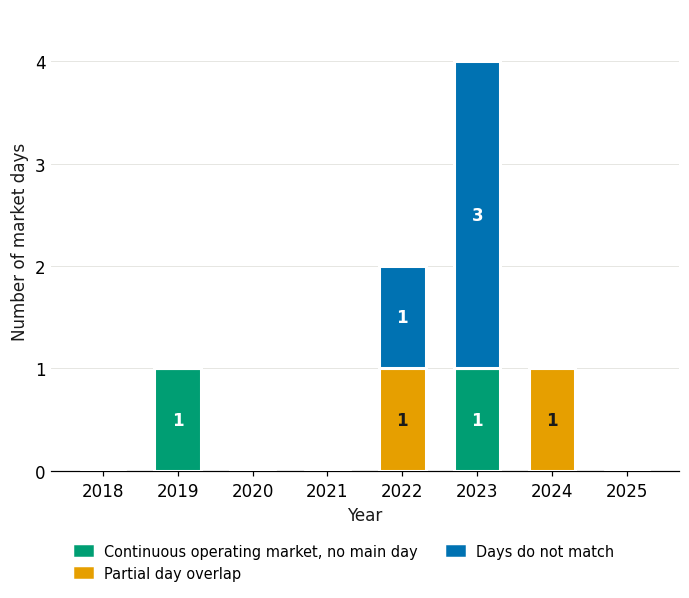

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\timing_weekday_activity_signals_A.png

Timing of weekday activity signals, panel B: First year with a signal (activity_area_norm2022, 2018-2025)
Field-only days with a signal in 2025: 7 days across 7 markets
Note: A signal is a one-sided Welch test with p < 0.05 against the weekdays that neither source names (no-main-day markets: Friday against the other six days). Dates describe satellite signals, not the start or end of trading. Days first seen in 2018 or 2019, the start of the data, are dated to the second of their first two consecutive years with a signal.


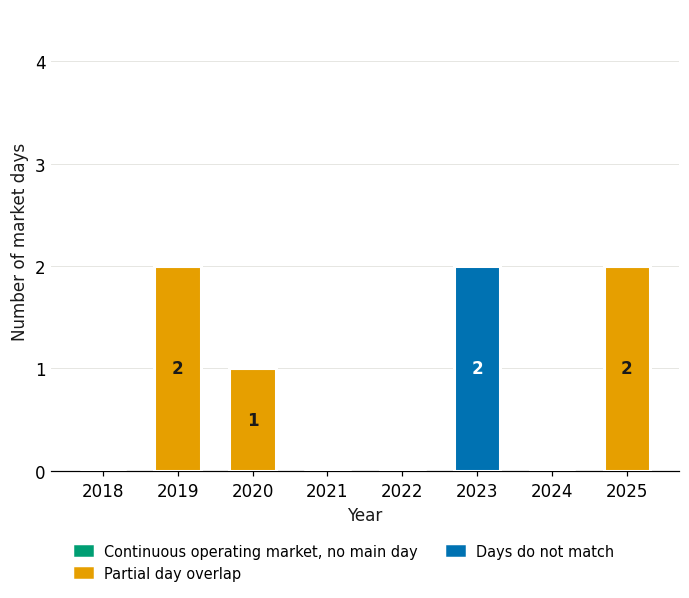

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\timing_weekday_activity_signals_B.png


In [328]:
# --- Figures: timing of weekday activity signals --------------------------------------
# Figure A: predicted days with no market-day signal in 2025 -> last year with a signal.
# Figure B: field-only days with a signal in 2025 -> first year with a signal.
# timing_table and plot_timing are reused for the second activity measure below.
YEARS_T = list(range(2018, 2026))
CATEGORY = {"A": "Continuous operating market, no main day", "B": "Partial day overlap",
            "C": "Partial day overlap", "D": "Partial day overlap", "E": "Days do not match"}
CAT_COLORS = {"Continuous operating market, no main day": "#009E73",      # Okabe-Ito
              "Partial day overlap": "#E69F00", "Days do not match": "#0072B2"}
CAT_INK = {"Continuous operating market, no main day": "white", "Partial day overlap": INK,
           "Days do not match": "white"}
NAMED_BY = {"overlap": "both sources", "ours-only": "MAI only", "predicted": "MAI",
            "field-only": "field only", "field": "field only"}
CONFIRM_YEARS = (2018, 2019)                       # first years at the start of the data


def confirmed_start(years, first):
    """Panel B year. A day first seen in 2018 or 2019 is dated to the second of its first two
    consecutive years with a signal; later first years are kept. None if no such pair exists."""
    if first not in CONFIRM_YEARS:
        return first
    ys = {int(y) for y in years.split(", ")}
    return next((y + 1 for y in sorted(ys) if y >= first and y + 1 in ys), None)


def timing_counts(t):
    """(days, markets) in each panel."""
    return {p: (int((t.panel == p).sum()), t.loc[t.panel == p, "mktID"].nunique()) for p in ("A", "B")}


def n_days_markets(n):
    """'9 days across 8 markets' for a (days, markets) pair."""
    return f"{n[0]} day{'s' * (n[0] != 1)} across {n[1]} market{'s' * (n[1] != 1)}"


def timing_table(res, fu_a, pred_no, field_yes):
    """Figure data. fu_a: Group A follow-ups by year ({district: by_year table}); pred_no: timing()
    summaries of predicted days with no signal in 2025; field_yes: of field-only days with one."""
    rows = []
    for name, t in fu_a.items():                   # Group A: Friday vs the other six days, by year
        m = t.mktID.iloc[0]
        if res.loc[res.mktID == m, "assigned_to"].iloc[0] != "Field":
            continue                               # Friday peak still present in 2025
        yes = t.loc[t.market_like == "yes", "year"]
        rows.append({"panel": "A", "group": "A", "district": name, "mktID": m, "day": "Fri",
                     "named_by": "MAI", "first_year": np.nan, "year": yes.max() if len(yes) else np.nan})
    for t in pred_no:                              # predicted days with no signal in 2025
        for r in t.itertuples():
            rows.append({"panel": "A", "group": r.group, "district": r.district, "mktID": r.mktID,
                         "day": r.day, "named_by": NAMED_BY[r.role], "first_year": np.nan,
                         "year": r.last_year_market_like})
    for t in field_yes:                            # field-only days with a signal in 2025
        for r in t.itertuples():
            rows.append({"panel": "B", "group": r.group, "district": r.district, "mktID": r.mktID,
                         "day": r.day, "named_by": NAMED_BY[r.role], "first_year": r.first_year_market_like,
                         "year": confirmed_start(r.years_market_like, r.first_year_market_like)})
    t = pd.DataFrame(rows, columns=["panel", "group", "district", "mktID", "day", "named_by", "first_year", "year"])
    t[["first_year", "year"]] = t[["first_year", "year"]].astype("Int64")
    t.insert(1, "category", t.group.map(CATEGORY))

    n_t = timing_counts(t)
    print(f"Panel A, predicted days with no signal in {YEAR}: {n_days_markets(n_t['A'])}")
    print(f"Panel B, field-only days with a signal in {YEAR}: {n_days_markets(n_t['B'])}")
    for label, s in [("No signal in any year 2018-2025", t[t.year.isna() & t.first_year.isna()]),
                     ("First seen in 2018-2019 but never two consecutive years",
                      t[t.year.isna() & t.first_year.notna()])]:
        if len(s):
            print(f"{label} (not plotted):", "; ".join(f"{r.district} {r.day}" for r in s.itertuples()))
    display(t)
    return t


NOTE_BASE = ("A signal is a one-sided Welch test with p < 0.05 against the weekdays that neither "
             "source names (no-main-day markets: Friday against the other six days). "
             "Dates describe satellite signals, not the start or end of trading.")
TIMING_PANELS = {
    "A": dict(title="Last year with a signal", what="Predicted days with no signal in 2025", note=NOTE_BASE),
    "B": dict(title="First year with a signal", what="Field-only days with a signal in 2025",
              note=NOTE_BASE + " Days first seen in 2018 or 2019, the start of the data, are dated to the "
              "second of their first two consecutive years with a signal."),
}


def plot_timing_panel(t, pnl, top, fname):
    """Bare figure of stacked yearly counts for panel `pnl` (y-axis 0..top), coloured by market category."""
    sub_p = t[t.panel == pnl].dropna(subset=["year"])
    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    bottom = np.zeros(len(YEARS_T))
    for cat, col in CAT_COLORS.items():
        sub = sub_p[sub_p.category == cat]
        if sub.empty:
            continue
        cnt = sub.year.value_counts().reindex(YEARS_T, fill_value=0).to_numpy()
        ax.bar(YEARS_T, cnt, bottom=bottom, width=0.62, color=col, edgecolor="white", linewidth=2, zorder=3)
        for x, c, b in zip(YEARS_T, cnt, bottom):
            if c:
                ax.text(x, b + c / 2, str(c), ha="center", va="center", color=CAT_INK[cat],
                        fontsize=11, fontweight="bold", zorder=4)
        bottom += cnt
    ax.set_xticks(YEARS_T)
    ax.set_xlabel("Year", color=INK)
    ax.set_ylabel("Number of market days", color=INK)
    ax.set_ylim(0, top + 0.5)
    ax.set_yticks(range(0, top + 1))
    grid(ax)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis="y", length=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in CAT_COLORS.items()]
    legend = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2,
                        frameon=False, fontsize=9.5, handlelength=1.2)
    fig.tight_layout()
    f = os.path.join(OUT_VAL, fname)
    fig.savefig(f, bbox_inches="tight", bbox_extra_artists=[legend])
    plt.show()
    print("saved", f)


def plot_timing(t, var, fname):
    """Two independent figures on the same y-axis; titles and notes are printed above each figure.
    Files are fname with _A / _B before the extension."""
    n_t = timing_counts(t)
    counts = t.dropna(subset=["year"]).groupby(["panel", "year"]).size()
    top = max(int(counts.max()) if len(counts) else 0, 1)
    stem, ext = os.path.splitext(fname)
    for pnl, spec in TIMING_PANELS.items():
        print(f"\nTiming of weekday activity signals, panel {pnl}: {spec['title']} ({var}, "
              f"{YEARS_T[0]}-{YEARS_T[-1]})")
        print(f"{spec['what']}: {n_days_markets(n_t[pnl])}")
        print(f"Note: {spec['note']}")
        plot_timing_panel(t, pnl, top, f"{stem}_{pnl}{ext}")


# Overlap days (named by both sources) without a 2025 signal; the other day sets were dated above.
OV_BOTH_NO_T, OV_BOTH_NO_Y = timing(OV[(OV.role == "overlap") & (OV.distinctive == "no")])
GROUP_SHEETS["Overlap B-D"]["Overlap days without distinctive activity in 2025: last year with market-day activity"] = OV_BOTH_NO_T
GROUP_SHEETS["Overlap B-D"]["Overlap days without distinctive activity in 2025, by year"] = OV_BOTH_NO_Y
TIMING = timing_table(RES, FU_A, [OV_BOTH_NO_T, OV_OURS_NO_T, E_PRED_NO_T], [OV_FIELD_T, E_FIELD_T])
GROUP_SHEETS["Timing"] = {"Timing of weekday activity signals (figure data)": TIMING}
plot_timing(TIMING, ACTIVITY_VAR, "timing_weekday_activity_signals.png")


## Summary table: markets by category and market-day activity signal

All 137 markets by how the satellite-detected (MAI) days compare with the field validation. For the
43 tested markets, the table also gives the share of **days** in each signal class (2025):

- **Above non-market days:** the day's mean activity is higher than on the comparison days (p < 0.05,
  one-tailed Welch). For the 4 markets with no main day, the MAI Friday is compared with the other six
  days. For the 5 markets with no trading day reported (group F), the detected day is compared with the
  other weekdays. For the partial and no-match markets, each day is compared with the weekdays that neither
  source names.
- **Not above non-market days:** p >= 0.05. This includes days whose mean is lower.
- **Insufficient data:** no 2025 readings on that day, or a market where the activity variable runs
  opposite to raw activity (not tested). Days with few readings keep their test result.

The exact-match rows are not tested in this notebook, so their figures are entered by hand.

In [329]:
# --- Table: markets by category and market-day activity signal ----------------------
# Exact-match rows are entered by hand (not tested here); the rows for the 43 tested markets
# (groups A-F) come from the tests above. summary_table is
# reused for the second activity measure below.
N_TOTAL = 137
SIGNAL = {"yes": "Above non-market days", "no": "Not above non-market days",
          "no data": "Insufficient data"}
PCT_COLS = ["Share of markets", *SIGNAL.values()]
pct = lambda v: "" if pd.isna(v) else v if isinstance(v, str) else f"{v:.0%}"
num = lambda v: "" if pd.isna(v) else f"{int(v)}"


def tab_row(category, days="", n_markets=np.nan, flags=None, given=None):
    """One table row. `flags` are day-level 'yes' / 'no' / 'no data' results; `given` are
    hand-entered shares (above, not above, insufficient) or 'NA'."""
    row = {"Category": category, "Days named by": days, "Markets": n_markets,
           "Share of markets": n_markets / N_TOTAL, "Days tested": np.nan}
    if flags is not None:
        c = flags.value_counts().reindex(list(SIGNAL), fill_value=0)
        row["Days tested"] = int(c.sum())
        row.update({SIGNAL[k]: c[k] / c.sum() for k in SIGNAL})
    elif given is not None:
        row.update(dict(zip(SIGNAL.values(), [given] * 3 if given == "NA" else given)))
    return row


def summary_table(res, ov, ed, var):
    """The summary table for one activity variable, displayed and saved to Excel."""
    a_flags = res.loc[res.group == "A", "p_one_tailed"].map(distinctive)
    f_flags = res.loc[res.group == "F", "p_one_tailed"].map(distinctive)
    t = pd.DataFrame([
        tab_row("Exact match", "Complete day overlap", 86, given=(1.0, 0.0, 0.0)),
        tab_row("Exact match", "Continuously operating markets", 8, given=(0.5, 0.5, 0.0)),
        tab_row("Continuous operating market, no main day", "MAI (Fri vs other six days)", len(a_flags), a_flags),
        tab_row("Partial day overlap", n_markets=len(OV_MKTS)),
        tab_row("", "Both sources", flags=ov.loc[ov.role == "overlap", "distinctive"]),
        tab_row("", "MAI only", flags=ov.loc[ov.role == "ours-only", "distinctive"]),
        tab_row("", "Field only", flags=ov.loc[ov.role == "field-only", "distinctive"]),
        tab_row("Days do not match", n_markets=len(E_MKTS)),
        tab_row("", "MAI", flags=ed.loc[ed.role == "predicted", "distinctive"]),
        tab_row("", "Field", flags=ed.loc[ed.role == "field", "distinctive"]),
        tab_row("No trading day reported", "MAI (detected day vs other days)", len(f_flags), f_flags),
    ])
    assert t.Markets.sum() == N_TOTAL
    t = pd.concat([t, pd.DataFrame([tab_row("Total markets", "", N_TOTAL)])], ignore_index=True)
    print(f"Markets by category and market-day activity signal, {YEAR} ({var})")
    display(t.style.format({**{c: pct for c in PCT_COLS}, "Markets": num, "Days tested": num})
            .hide(axis="index"))

    path = os.path.join(OUT_VAL, f"market_day_validation_table_{YEAR}_{var}.xlsx")
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        t.to_excel(xw, sheet_name="table", index=False)
        ws = xw.sheets["table"]
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = max(len(str(c.value or "")) for c in col) + 2
            if col[0].value in PCT_COLS:
                for c in col[1:]:
                    c.number_format = "0%"
    print("saved", path)
    return t


TABLE = summary_table(RES, OV, ED, ACTIVITY_VAR)

Markets by category and market-day activity signal, 2025 (activity_area_norm2022)


Category,Days named by,Markets,Share of markets,Days tested,Above non-market days,Not above non-market days,Insufficient data
Exact match,Complete day overlap,86,63%,,100%,0%,0%
Exact match,Continuously operating markets,8,6%,,50%,50%,0%
"Continuous operating market, no main day",MAI (Fri vs other six days),4,3%,4,50%,50%,0%
Partial day overlap,,21,15%,,,,
,Both sources,,,22,95%,5%,0%
,MAI only,,,8,88%,12%,0%
,Field only,,,19,26%,74%,0%
Days do not match,,13,9%,,,,
,MAI,,,17,76%,24%,0%
,Field,,,17,12%,88%,0%


saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\market_day_validation_table_2025_activity_area_norm2022.xlsx


## Overall summary

In [330]:
# --- Overall: Group A verdicts, day-level counts and timing --------------------------
A_RES = RES[RES.group == "A"][["district", "mktID", "p_one_tailed", "assigned_to"]]
print(f"Group A ({YEAR}): detected Friday vs the other six days")
display(A_RES.round(3))
F_RES = RES[RES.group == "F"][["district", "mktID", "detected_days", "p_one_tailed", "assigned_to"]]
print(f"Group F ({YEAR}): detected day vs the other weekdays")
display(F_RES.round(3))
print("Partially overlapping schedules (21 markets): days with distinctive market-day activity")
display(OV_COUNTS)
print(f"No overlapping day ({len(E_MKTS)} markets): days with activity above the non-market days")
display(E_COUNTS)

Group A (2025): detected Friday vs the other six days


,district,mktID,p_one_tailed,assigned_to
0,Andar,lon68_4423lat33_3241,0.452,Field
1,Maydanshahr,lon68_8689lat34_397,0.964,Field
2,Birmil,lon69_3307lat32_7698,0.000,MAI
3,Urgun,lon69_1698lat32_9516,0.000,MAI


Group F (2025): detected day vs the other weekdays


,district,mktID,detected_days,p_one_tailed,assigned_to
38,(not in WFP list),lon68_7092lat35_9503,Fri,NaN,Neither
39,(not in WFP list),lon69_5107lat35_9643,Mon,0.0,MAI
40,Maywand,lon64_7811lat31_6409,Thu,0.0,MAI
41,Maywand,lon64_8951lat31_546,Sun,0.0,MAI
42,Mahmud-e-Raqi,lon69_3316lat35_0459,Sat,0.0,MAI


Partially overlapping schedules (21 markets): days with distinctive market-day activity


distinctive,yes,no,no data,days,markets,markets_with_a_distinctive_day
role,,,,,,
overlap,21,1,0,22,21,20
ours-only,7,1,0,8,8,7
field-only,5,14,0,19,17,5


No overlapping day (13 markets): days with activity above the non-market days


distinctive,yes,no,no data,days,markets,markets_with_a_distinctive_day
role,,,,,,
predicted,13,4,0,17,13,10
field,2,15,0,17,13,2


In [331]:
# --- Workbook: Group A, the 21 overlapping markets and the 14 non-overlapping markets ---
SHEET_NAME = {"A": "Group A", "Overlap B-D": "Overlap B-D (21)", "No overlap E": "No overlap E (13)",
              "F": "Group F (5)"}


def write_by_group(var, summary_parts, group_sheets):
    """One workbook per activity variable: a summary sheet and one sheet per set of markets."""
    path = os.path.join(OUT_VAL, f"market_day_validation_by_group_{YEAR}_{var}.xlsx")
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        for sheet, parts in [("Summary", summary_parts)] + [(SHEET_NAME.get(k, k), v) for k, v in group_sheets.items()]:
            row = 0
            for title, t in parts.items():
                t.to_excel(xw, sheet_name=sheet, startrow=row + 1, index=False)
                ws = xw.sheets[sheet]
                ws.cell(row=row + 1, column=1, value=title).font = Font(bold=True, size=12)
                row += len(t) + 4
            ws = xw.sheets[sheet]
            for col in ws.columns:
                vals = [len(str(c.value)) for c in col if c.value is not None and c.row > 1]
                ws.column_dimensions[col[0].column_letter].width = min((max(vals) if vals else 8) + 2, 45)
    print("saved", path)
    for k, parts in group_sheets.items():
        print(f"  {SHEET_NAME.get(k, k)}: " + "; ".join(f"{t} ({len(v)} rows)" for t, v in parts.items()))


write_by_group(ACTIVITY_VAR,
               {f"Group A, {YEAR}": A_RES, f"Group F, {YEAR}": F_RES,
                "Partially overlapping schedules: days with distinctive activity": OV_COUNTS.reset_index(),
                "No overlapping day: days with activity above the non-market days": E_COUNTS.reset_index()},
               GROUP_SHEETS)

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\market_day_validation_by_group_2025_activity_area_norm2022.xlsx
  Group A: Main tests, 2025 (4 rows); Follow-up: Maydanshahr by year (8 rows); Follow-up: Andar by year (8 rows)
  Overlap B-D (21): Day-level tests, 2025 (each day vs the days neither source names) (49 rows); Counts by role, 2025 (3 rows); Direct comparison, ours-only vs field-only days, 2025 (4 rows); Field-only days with distinctive activity in 2025: first year of market-day activity (5 rows); Field-only days with distinctive activity in 2025, by year (40 rows); Ours-only days with distinctive activity in 2025: last year without market-day activity (7 rows); Ours-only days with distinctive activity in 2025, by year (56 rows); Ours-only days without distinctive activity in 2025: last year with market-day activity (1 rows); Ours-only days without distinctive activity in 2025, by year (8 

**Overall (`activity_area_norm2022`, 2025)**

- **Continuous trading, no main day (4 markets):** Birmil and Urgun still show a Friday peak. Andar and Maydanshahr do not, which is consistent with the field report. Andar lost its Friday peak in 2024.
- **Partially overlapping schedules (21 markets):** the days both sources name almost always show distinctive market-day activity (21 of 22), and so do the days only the algorithm names (7 of 8). Only 5 of the 19 days that only the field names do.
- **No overlapping day (13 markets):** 13 of the 17 predicted days are above the non-market days, against 2 of the 17 field days. The two field days, in Nawzad and Bakwa, look like market days that moved in 2023.
- **No field-validated market day (5 markets):** all 4 testable markets show a weekly peak on the detected day in every year from 2018 to 2025, including the two Maywand locations where the field found no bazaar. The fifth (Baghlan lon68_7092) is not tested because the activity variable runs opposite to raw activity there.
- **Timing:** of the 8 predicted days with no signal in 2025 (7 markets), 7 last showed one in 2022 or later. Of the 7 field-only days with a signal in 2025, 4 first show it in 2023 or 2025. The other 3 were established by 2019 or 2020.

## Mirror: the same tests with `activity_measure` (asleep)

**Switched off:** the code cells in this section are commented out; the analysis focuses on `activity_area_norm2022`. Uncomment them to run the mirror again.

Every market-day validation test above, rerun with `activity_measure` (the raw activity measure, not
normalized; always positive) in place of the main variable (`ACTIVITY_VAR`). The markets, day sets, years,
thresholds and the one-reading-per-market-per-date panel are the same. `activity_measure` is missing on
about one row in five, so some weekdays have fewer readings (see the coverage report).

Results carry a `_2` suffix (`RES_2`, `OV_2`, `ED_2`, ...). Output files are named by measure, so the
main variable's files are not overwritten. The last cells compare the two measures.

In [332]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Mirror: data, coverage and the 2025 tests with activity_measure ------------------
# VAR_2 = "activity_measure"
# GROUP_SHEETS_2 = {"A": {}, "Overlap B-D": {}, "No overlap E": {}}
# PANEL_2, has_read_2 = build_panel(VAR_2)
# notes_2 = coverage_report(VAR_2, PANEL_2, has_read_2)
# RES_2 = run_tests(VAR_2, PANEL_2, has_read_2, notes_2)
# write_excel(RES_2, VAR_2)

### Group A with `activity_measure`

Main test as above (detected Friday vs the other six days). The follow-up by year covers all four
markets, because the markets without a Friday peak in 2025 can differ between the measures.

In [333]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# show_main("A", RES_2, PANEL_2, VAR_2, GROUP_SHEETS_2)
#
# FU_A_2 = {}
# for m, r in MKT[MKT.group == "A"].iterrows():
#     t = by_year(m, {FRI}, var=VAR_2)
#     t["same_every_day"] = np.where(t.p_test_gt_other.isna() | t.p_anova_equal_days.isna(), "n/a",
#                                    np.where((t.p_test_gt_other >= ALPHA) & (t.p_anova_equal_days >= ALPHA), "yes", "no"))
#     FU_A_2[r.district] = t
#     GROUP_SHEETS_2["A"][f"Follow-up: {r.district} by year"] = t
#     print(f"{r.district} ({m}): Friday vs the other six days, by year")
#     display(t[BY_YEAR_SHOW + ["same_every_day"]].round(3))

### Partially overlapping schedules with `activity_measure` (21 markets: groups B, C and D)

In [334]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# OV_2 = day_tests(OV_MKTS, panel=PANEL_2)
# OV_COUNTS_2 = day_counts(OV_2, OV_ROLE_ORDER)
# print(f"{len(OV_MKTS)} markets with partially overlapping schedules; days with distinctive market-day "
#       f"activity in {YEAR} ({VAR_2}, vs the days neither source names):")
# display(OV_COUNTS_2)
# for role in OV_ROLE_ORDER:
#     print(f"\n{role} days with distinctive activity: {list_days(OV_2, role)}")
#     print(f"{role} days without data: {list_days(OV_2, role, 'no data')}")
# GROUP_SHEETS_2["Overlap B-D"]["Day-level tests, 2025 (each day vs the days neither source names)"] = OV_2
# GROUP_SHEETS_2["Overlap B-D"]["Counts by role, 2025"] = OV_COUNTS_2.reset_index()
# display(OV_2[["group", "district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day",
#               "mean_comparison", "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))
#
# # Disputed days compared directly: ours-only vs field-only (markets that have both)
# OV_DIRECT_2 = direct(OV_MKTS, "ours-only", "field-only", panel=PANEL_2)
# GROUP_SHEETS_2["Overlap B-D"]["Direct comparison, ours-only vs field-only days, 2025"] = OV_DIRECT_2
# print(f"{len(OV_DIRECT_2)} markets have both ours-only and field-only days:")
# display(OV_DIRECT_2.round(3))
# for g in ["B", "C", "D"]:
#     plot_markets(MKT.index[MKT.group == g].tolist(), f"Group {g}: {GROUP_TITLE[g]}",
#                  f"weekday_profile_{VAR_2}_group_{g}.png", panel=PANEL_2, var=VAR_2)

In [335]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # Timing (2018-2025) with activity_measure
# OV_FIELD_T_2, OV_FIELD_Y_2 = timing(OV_2[(OV_2.role == "field-only") & (OV_2.distinctive == "yes")], VAR_2)
# OV_OURS_T_2, OV_OURS_Y_2 = timing(OV_2[(OV_2.role == "ours-only") & (OV_2.distinctive == "yes")], VAR_2)
# OV_OURS_NO_T_2, OV_OURS_NO_Y_2 = timing(OV_2[(OV_2.role == "ours-only") & (OV_2.distinctive == "no")], VAR_2)
# for title, t, y, cols in [
#         ("Field-only days with distinctive activity in 2025: first year of market-day activity",
#          OV_FIELD_T_2, OV_FIELD_Y_2, ["first_year_market_like", "market_like_since"]),
#         ("Ours-only days with distinctive activity in 2025: last year without market-day activity",
#          OV_OURS_T_2, OV_OURS_Y_2, ["last_year_not_market_like", "market_like_since"]),
#         ("Ours-only days without distinctive activity in 2025: last year with market-day activity",
#          OV_OURS_NO_T_2, OV_OURS_NO_Y_2, ["last_year_market_like"])]:
#     print(f"\n{title} ({len(t)} days)")
#     if len(t):
#         display(t[["group", "district", "mktID", "day", "years_market_like"] + cols])
#         GROUP_SHEETS_2["Overlap B-D"][title] = t
#         GROUP_SHEETS_2["Overlap B-D"][title.split(":")[0] + ", by year"] = y

### No overlapping operating day with `activity_measure` (13 markets: group E)

In [336]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# ED_2 = day_tests(E_MKTS, E_LABELS, panel=PANEL_2)
# E_COUNTS_2 = day_counts(ED_2, E_ROLE_ORDER)
# print(f"{len(E_MKTS)} markets with no overlapping day; days with activity above the non-market days in "
#       f"{YEAR} ({VAR_2}):")
# display(E_COUNTS_2)
# for role in E_ROLE_ORDER:
#     print(f"\n{role} days above the non-market days: {list_days(ED_2, role)}")
#     print(f"{role} days without data: {list_days(ED_2, role, 'no data')}")
# GROUP_SHEETS_2["No overlap E"]["Day-level tests, 2025 (each day vs the days neither source names)"] = ED_2
# GROUP_SHEETS_2["No overlap E"]["Counts by role, 2025"] = E_COUNTS_2.reset_index()
# display(ED_2[["district", "mktID", "role", "day", "n_day", "n_comparison", "mean_day", "mean_comparison",
#               "diff", "p_one_tailed", "distinctive", "low_power"]].round(3))
#
# # Predicted days vs field days, compared directly (pooled within each source)
# E_DIRECT_2 = direct(E_MKTS, "ours-only", "field-only", E_LABELS, panel=PANEL_2)
# GROUP_SHEETS_2["No overlap E"]["Direct comparison, predicted vs field days, 2025"] = E_DIRECT_2
# display(E_DIRECT_2.round(3))
# plot_markets(E_MKTS, f"Group E: {GROUP_TITLE['E']}", f"weekday_profile_{VAR_2}_group_E.png",
#              panel=PANEL_2, var=VAR_2)

In [337]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # Timing (2018-2025) with activity_measure
# E_PRED_T_2, E_PRED_Y_2 = timing(ED_2[(ED_2.role == "predicted") & (ED_2.distinctive == "yes")], VAR_2)
# E_FIELD_T_2, E_FIELD_Y_2 = timing(ED_2[(ED_2.role == "field") & (ED_2.distinctive == "yes")], VAR_2)
# E_PRED_NO_T_2, E_PRED_NO_Y_2 = timing(ED_2[(ED_2.role == "predicted") & (ED_2.distinctive == "no")], VAR_2)
# for title, t, y, cols in [
#         ("Predicted days above the non-market days in 2025: last year they stopped",
#          E_PRED_T_2, E_PRED_Y_2, ["last_year_not_market_like", "market_like_since"]),
#         ("Field days above the non-market days in 2025: first year they started",
#          E_FIELD_T_2, E_FIELD_Y_2, ["first_year_market_like", "market_like_since"]),
#         ("Predicted days not above the non-market days in 2025: last year they were",
#          E_PRED_NO_T_2, E_PRED_NO_Y_2, ["last_year_market_like"])]:
#     print(f"\n{title} ({len(t)} days)")
#     if len(t):
#         display(t[["district", "mktID", "day", "years_market_like"] + cols])
#         GROUP_SHEETS_2["No overlap E"][title] = t
#         GROUP_SHEETS_2["No overlap E"][title.split(":")[0] + ", by year"] = y

### Timing of weekday activity signals, summary table and overall results with `activity_measure`

In [338]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Mirror: timing figure, summary table and workbook --------------------------------
# OV_BOTH_NO_T_2, OV_BOTH_NO_Y_2 = timing(OV_2[(OV_2.role == "overlap") & (OV_2.distinctive == "no")], VAR_2)
# GROUP_SHEETS_2["Overlap B-D"]["Overlap days without distinctive activity in 2025: last year with market-day activity"] = OV_BOTH_NO_T_2
# GROUP_SHEETS_2["Overlap B-D"]["Overlap days without distinctive activity in 2025, by year"] = OV_BOTH_NO_Y_2
# TIMING_2 = timing_table(RES_2, FU_A_2, [OV_BOTH_NO_T_2, OV_OURS_NO_T_2, E_PRED_NO_T_2], [OV_FIELD_T_2, E_FIELD_T_2])
# GROUP_SHEETS_2["Timing"] = {"Timing of weekday activity signals (figure data)": TIMING_2}
# plot_timing(TIMING_2, VAR_2, f"timing_weekday_activity_signals_{VAR_2}.png")
#
# TABLE_2 = summary_table(RES_2, OV_2, ED_2, VAR_2)
#
# A_RES_2 = RES_2[RES_2.group == "A"][["district", "mktID", "p_one_tailed", "assigned_to"]]
# print(f"Group A ({YEAR}, {VAR_2}): detected Friday vs the other six days")
# display(A_RES_2.round(3))
# print("Partially overlapping schedules (21 markets): days with distinctive market-day activity")
# display(OV_COUNTS_2)
# print("No overlapping day (14 markets): days with activity above the non-market days")
# display(E_COUNTS_2)
# write_by_group(VAR_2,
#                {f"Group A, {YEAR}": A_RES_2,
#                 "Partially overlapping schedules: days with distinctive activity": OV_COUNTS_2.reset_index(),
#                 "No overlapping day: days with activity above the non-market days": E_COUNTS_2.reset_index()},
#                GROUP_SHEETS_2)

### Comparison: main variable vs `activity_measure`

In [339]:
# ASLEEP: activity_measure mirror switched off. Uncomment the lines below to run it.
# # --- Comparison of the two measures -------------------------------------------------
# V1, V2 = ACTIVITY_VAR, VAR_2
# KEY = ["group", "district", "mktID", "role", "day"]
#
# A_CMP = A_RES.merge(A_RES_2, on=["district", "mktID"], suffixes=(f"_{V1}", f"_{V2}"))
# print("Group A: Friday peak (MAI) or none (Field), by measure")
# display(A_CMP.round(3))
#
# DAY_CMP = pd.concat([d1[KEY + ["distinctive", "p_one_tailed"]].merge(
#                          d2[KEY + ["distinctive", "p_one_tailed"]], on=KEY, suffixes=(f"_{V1}", f"_{V2}"))
#                      for d1, d2 in [(OV, OV_2), (ED, ED_2)]], ignore_index=True)
# print(f"\nDay-level signal in {YEAR}: {V1} (rows) vs {V2} (columns), by role")
# display(pd.crosstab([DAY_CMP.role, DAY_CMP[f"distinctive_{V1}"]], DAY_CMP[f"distinctive_{V2}"]))
# DAY_DIFF = DAY_CMP[DAY_CMP[f"distinctive_{V1}"] != DAY_CMP[f"distinctive_{V2}"]]
# print(f"\n{len(DAY_DIFF)} of {len(DAY_CMP)} days change class between the measures:")
# display(DAY_DIFF.round(3))
#
# print("\nSummary table, by measure")
# display(pd.DataFrame({"Category": TABLE.Category, "Days named by": TABLE["Days named by"],
#                       **{f"{s} ({v})": t[s].map(pct) for s in SIGNAL.values() for v, t in [(V1, TABLE), (V2, TABLE_2)]}}))
#
# TIMING_CMP = TIMING[["panel", "district", "mktID", "day", "year"]].merge(
#     TIMING_2[["panel", "district", "mktID", "day", "year"]], on=["panel", "district", "mktID", "day"],
#     how="outer", suffixes=(f"_{V1}", f"_{V2}")).sort_values(["panel", "district", "day"])
# print("\nTiming figure data, by measure (blank: the day is not in that measure's panel)")
# display(TIMING_CMP)

**Summary: `activity_area_norm2020` vs `activity_measure`** (from the last run, when `activity_area_norm2020` was the main variable)

- **Coverage:** `activity_measure` has no 2025 reading on some weekdays in some markets:
  - Nawzad Thu and Bakwa Sat have none at all. These are the two field-reported days that the area measure
    finds as market days that started in 2023, so the schedule change in those markets cannot be checked with
    this measure.
  - The comparison days of Nahr-e-Saraj lon64_4065 have a single reading, so none of its three days can be
    tested.
  - In Andar, under 40% of non-Friday images have a reading.
- **Group A:** Maydanshahr still shows no Friday peak (p = 0.36), and Birmil and Urgun still show one. Andar
  now shows a Friday peak in 2025 (p < 0.001), but on low coverage of the other six days (55 dates against
  151 with the area measure).
- **Day level:** 15 of the 85 days change class.
  - **8 gain a signal:** seven predicted days (Nad-e-Ali lon64_0787 Tue, Almar lon64_5285 Fri, Murghab Mon,
    Kajaki Sun and Wed, Nawzad Sat, Bakwa Fri) and one field-only day (Nahr-e-Saraj lon64_7449 Mon).
  - **2 lose it:** the field-only days Alishang Tue and Muhmanddara Fri.
  - **5 have no data:** the three Nahr-e-Saraj lon64_4065 days, Nawzad Thu and Bakwa Sat.
- **Summary table:** with `activity_measure`, every predicted day in the no-match markets is above the
  non-market days (18 of 18, against 14 with the area measure), and no field day is (0 of 18, 2 with no
  data). MAI-only days in the partial-overlap markets rise from 75% to 88%.
- **Timing:**
  - **Panel A:** only Maydanshahr Fri remains, with its last signal in 2023 (2019 with the area measure).
  - **Panel B:** four field-only days. Qades Sat is dated 2019, Washer lon64_3886 Fri 2020, Washer
    lon64_2906 Sat 2021 and Nahr-e-Saraj lon64_7449 Mon 2025. The two Washer days have few 2025 readings
    (4 and 7 dates).

## Markets by goods sold

All 137 markets by the goods the WFP field validation reports (`market_validation_corrected.xlsx`, sheet
"Market list", column `category_label`). Car markets are the markets selling general goods only. Two
Baghlan markets are not in the WFP list.

In [340]:
# --- Table: markets by goods sold -----------------------------------------------------
GOODS_XLSX = os.path.join(DATA, "WFP_validation", "market_validation_corrected.xlsx")
GOODS_ROWS = [   # (block, row, category_label values)
    ("Food is sold", "Food only", ["Food only"]),
    ("Food is sold", "Food and livestock", ["Food and livestock, no general goods"]),
    ("Food is sold", "Food and general goods", ["Food and general goods, no livestock", "All goods, unspecified"]),
    ("Food is sold", "Food, livestock and general goods", ["Food, livestock and general goods"]),
    ("Food not sold", "Livestock only", ["Livestock only"]),
    ("Food not sold", "General goods only (car markets)", ["General goods only"]),
    ("Not specified", "", ["Not specified"]),
]

goods = pd.read_excel(GOODS_XLSX, sheet_name="Market list")[["mktID", "category_label", "car_market"]]
goods = pd.DataFrame({"mktID": sorted(df_act.mktID.unique())}).merge(goods, on="mktID", how="left")
label_row = {lab: (blk, row) for blk, row, labs in GOODS_ROWS for lab in labs}
unmapped = set(goods.category_label.dropna()) - set(label_row)
assert not unmapped, f"goods labels without a table row: {unmapped}"
car = goods.car_market.astype(str).str.strip().str.lower().eq("yes")
print(f"car markets: {car.sum()}; general-goods-only markets: {(goods.category_label == 'General goods only').sum()}; "
      f"car markets with another label: {(car & (goods.category_label != 'General goods only')).sum()}")

goods["block"] = goods.category_label.map(lambda l: label_row[l][0] if l in label_row else "Not in WFP list")
goods["row"] = goods.category_label.map(lambda l: label_row[l][1] if l in label_row else "")
order = [(blk, row) for blk, row, _ in GOODS_ROWS] + [("Not in WFP list", "")]
GOODS_TABLE = (goods.groupby(["block", "row"]).size().reindex(pd.MultiIndex.from_tuples(order), fill_value=0)
               .rename("No. markets").reset_index().rename(columns={"level_0": "Goods", "level_1": ""}))
GOODS_TABLE["Share (%)"] = GOODS_TABLE["No. markets"] / GOODS_TABLE["No. markets"].sum()
GOODS_TABLE = pd.concat([GOODS_TABLE, pd.DataFrame([{"Goods": "Total markets", "": "",
                                                     "No. markets": GOODS_TABLE["No. markets"].sum(),
                                                     "Share (%)": 1.0}])], ignore_index=True)
assert GOODS_TABLE["No. markets"].iloc[-1] == N_TOTAL
GOODS_TABLE.loc[GOODS_TABLE.Goods.duplicated(), "Goods"] = ""         # show each block name once
display(GOODS_TABLE.style.format({"Share (%)": "{:.0%}"}).hide(axis="index"))

f = os.path.join(OUT_VAL, "markets_by_goods.xlsx")
with pd.ExcelWriter(f, engine="openpyxl") as xw:
    GOODS_TABLE.to_excel(xw, sheet_name="goods", index=False)
    goods.to_excel(xw, sheet_name="markets", index=False)
    for ws in xw.sheets.values():
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = max(len(str(c.value or "")) for c in col) + 2
    for c in xw.sheets["goods"]["D"][1:]:
        c.number_format = "0%"
print("saved", f)

car markets: 3; general-goods-only markets: 3; car markets with another label: 0


Goods,,No. markets,Share (%)
Food is sold,Food only,29,21%
,Food and livestock,9,7%
,Food and general goods,28,20%
,"Food, livestock and general goods",48,35%
Food not sold,Livestock only,8,6%
,General goods only (car markets),3,2%
Not specified,,10,7%
Not in WFP list,,2,1%
Total markets,,137,100%


saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\market_day_validation\markets_by_goods.xlsx


## Market activity across the year

Seasonality of market-day activity for all markets, 2018-2025, with `activity_area_norm2020`.

- **Specification E** (from `panel_E_figure.py`): `act ~ 0 + quarter x goods category + year dummies +
  access dummies`, on market-quarter means of market-day activity. Readings below -5 or above 300 are dropped. Only
  market-years with all four quarters are kept. Standard errors are clustered on market, with 90% confidence intervals. Goods categories come
  from the WFP validation (`market_validation_corrected.xlsx`, sheet "Market list", column `category_label`), and access from
  `markets_periodic_access_BNR_2018_2025.csv`. Each category's quarterly levels are centred on its own mean
  before plotting.
- **Secondary regressions:** E2 keeps every market-year, even without all four quarters, with heteroskedasticity-robust
  (HC1) standard errors. E3 is E2 without the year and access controls.
- **Market-level index:** specification E on a quarterly index, 100 x the market-quarter mean / the mean of that
  market-year's four quarterly means, so each market-year averages 100.
- **Monthly activity by year:** mean market-day activity by calendar month, one line per year, for all 137
  markets.

In [ ]:
# --- Specification E: settings, data and estimation (from panel_E_figure.py) ----------
import statsmodels.formula.api as smf

PE_Z = 1.6449                                   # 90% two-sided normal quantile
PE_ORDER = ["Food and other goods", "Food only", "Livestock only", "Car markets"]
PE_SH = {"Food and other goods": "FO", "Food only": "FD", "Livestock only": "LV", "Car markets": "CA"}
PE_COL = {"Food and other goods": "#2a78d6", "Food only": "#eb6834",
          "Livestock only": "#1baf7a", "Car markets": "#4a3aa7"}
PE_MRK = {"Food and other goods": "o", "Food only": "s", "Livestock only": "^", "Car markets": "D"}
PE_DODGE = {"Food and other goods": -0.105, "Food only": -0.035, "Livestock only": 0.035, "Car markets": 0.105}
# Grouping by market access instead of goods (same estimation and figure; access colours as in the
# paper's access-category figures)
PA_ORDER = ["High access", "Intermediate access", "Remote"]
PA_SH = {"High access": "HI", "Intermediate access": "IN", "Remote": "RE"}
PA_STYLE = dict(order=PA_ORDER,
                col={"High access": "#1baf7a", "Intermediate access": "#eb6834", "Remote": "#2a78d6"},
                mrk={"High access": "o", "Intermediate access": "s", "Remote": "^"},
                dodge={"High access": -0.08, "Intermediate access": 0.0, "Remote": 0.08})
PE_INK, PE_INK2, PE_INK3, PE_SURF = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb"
PE_YLIM = (-58, 58)
PE_MIN, PE_MAX = -5, 300                        # market-day readings outside this range are dropped

PE_ACCESS = os.path.join(DATA, "markets_periodic_access_BNR_2018_2025.csv")
PE_CATS = os.path.join(DATA, "WFP_validation", "market_validation_corrected.xlsx")
FOOD_AND_OTHER = {"Food, livestock and general goods", "Food and livestock, no general goods",
                  "Food and general goods, no livestock", "All goods, unspecified"}
OUT_SEAS = os.path.join(OUTPUT, "seasonality")
os.makedirs(OUT_SEAS, exist_ok=True)


def pe_build(full_years=True, index=False, by="goods"):
    """Market-quarter means of market-day activity, 2018-2025, with goods group and access.
    full_years=True keeps only market-years with all four quarters. index=True replaces the quarter's
    mean with a market-level index: 100 x quarter mean / mean of that market-year's quarterly means.
    by="goods" groups markets by goods sold (markets without a goods category are left out);
    by="access" groups them by the three access categories (every market has one)."""
    d = df_act[["date", "mktID", "mktDay", "activity_area_norm2020", "image_id"]].rename(columns={"mktID": "Location"})
    d = d[(d.mktDay == 1) & d.activity_area_norm2020.between(PE_MIN, PE_MAX)]
    d["year"], d["quarter"] = d.date.dt.year, d.date.dt.quarter
    d = d[(d.year >= 2018) & (d.year <= 2025)]

    q = (d.groupby(["Location", "year", "quarter"])
           .agg(act=("activity_area_norm2020", "mean"), n_img=("image_id", "size")).reset_index())
    if full_years:
        full = q.groupby(["Location", "year"]).quarter.nunique()
        q = q.set_index(["Location", "year"]).loc[full[full == 4].index].reset_index()
    if index:                                   # market-year mean = 100
        q["act_level"] = q.act
        q["act"] = 100 * q.act / q.groupby(["Location", "year"]).act.transform("mean")

    if by == "access":
        q = q.merge(pd.read_csv(PE_ACCESS)[["mktID", "access"]], left_on="Location", right_on="mktID", how="left")
        assert q.access.notna().all()
        q["group"] = q.access
        cells = [PA_SH[g] + "_Q" + str(k) for g in PA_ORDER for k in range(1, 5)]
        q["cell"] = pd.Categorical(q.group.map(PA_SH) + "_Q" + q.quarter.astype(str), categories=cells, ordered=True)
        q["yr"] = q.year.astype(str)
        return q

    # Goods categories from the WFP validation (category_label); car_market is "yes" or blank there.
    cats = pd.read_excel(PE_CATS, sheet_name="Market list")[["mktID", "category_label", "car_market"]]
    cats["car_market"] = cats.car_market.astype(str).str.strip().str.lower().eq("yes").astype(int)
    q = q.merge(cats, left_on="Location", right_on="mktID", how="left")

    def group_of(r):
        if r.car_market == 1:
            return "Car markets"
        if r.category_label == "Livestock only":
            return "Livestock only"
        if r.category_label == "Food only":
            return "Food only"
        if r.category_label in FOOD_AND_OTHER:
            return "Food and other goods"
        return None

    q["group"] = q.apply(group_of, axis=1)
    q = q.dropna(subset=["group"])
    q = q.merge(pd.read_csv(PE_ACCESS)[["mktID", "access"]], on="mktID", how="left")
    assert q.access.notna().all()

    cells = [PE_SH[g] + "_Q" + str(k) for g in PE_ORDER for k in range(1, 5)]
    q["cell"] = pd.Categorical(q.group.map(PE_SH) + "_Q" + q.quarter.astype(str), categories=cells, ordered=True)
    q["yr"] = q.year.astype(str)
    return q


def pe_estimate(q, controls=True, cov="cluster", order=None, sh=None):
    """controls: year and access dummies. cov: "cluster" (on market) or a robust type such as "HC1".
    order / sh: the groups and their short cell codes (default: the goods groups)."""
    order = PE_ORDER if order is None else order
    sh = PE_SH if sh is None else sh
    formula = 'act ~ 0 + C(cell)'
    if controls:
        formula += ' + C(yr, Treatment("2018")) + C(access, Treatment("High access"))'
    fit_kw = dict(cov_type="cluster", cov_kwds={"groups": q.Location}) if cov == "cluster" else dict(cov_type=cov)
    m = smf.ols(formula, data=q).fit(**fit_kw)
    k = lambda g, j: f'C(cell)[{sh[g]}_Q{j}]'
    B = pd.DataFrame({f"Q{j}": [m.params[k(g, j)] for g in order] for j in range(1, 5)}, index=order)
    SE = pd.DataFrame({f"Q{j}": [m.bse[k(g, j)] for g in order] for j in range(1, 5)}, index=order)
    SW = {}
    for g in order:
        t = m.t_test(f"{k(g, 4)} - {k(g, 2)} = 0")
        SW[g] = (float(t.effect[0]), float(t.sd[0, 0]), float(t.pvalue))
    return m, B, SE, SW


PE_Q = pe_build()
PE_M, PE_B, PE_SE, PE_SW = pe_estimate(PE_Q)
print(f"{PE_Q.Location.nunique()} markets, {len(PE_Q):,} market-quarters, 2018-2025")
print("Markets by goods group:", PE_Q.groupby("group").Location.nunique().reindex(PE_ORDER).to_dict())
print("\nCell levels:")
display(PE_B.round(2))
print("Plotted (centred on each group's mean):")
display(PE_B.sub(PE_B.mean(axis=1), axis=0).round(2))
print("Q4 - Q2 swing (effect, SE, p):")
display(pd.DataFrame(PE_SW, index=["effect", "se", "p"]).T.round(3))

In [ ]:
# --- Specification E: figure (from panel_E_figure.py) ------------------------------------
def pe_draw(B, SE, SW, n_markets, n_obs, out, title="E.  Raw measure, controlling for year and market access",
            model="act ~ 0 + quarter \u00d7 goods category + year + access, no constant.\n"
                  "Year and access enter additively, not interacted with quarter.",
            se_note="clustered on market",
            ylabel="Deviation from the market\u2019s own mean\n(index points)", style=None):
    st = style or dict(order=PE_ORDER, col=PE_COL, mrk=PE_MRK, dodge=PE_DODGE)
    Bc = B.sub(B.mean(axis=1), axis=0)          # centre each group on its own mean
    label_y, prev = {}, -np.inf                 # direct labels at the Q4 level, at least 5.5 points apart
    for g, y in Bc["Q4"].sort_values().items():
        prev = label_y[g] = max(y, prev + 5.5)

    fig, ax = plt.subplots(figsize=(9.4, 6.0), facecolor=PE_SURF)
    ax.set_facecolor(PE_SURF)
    ax.axhline(0, color=PE_INK3, lw=1.0, zorder=1)
    for xi in (0.5, 1.5, 2.5):
        ax.axvline(xi, color="#edece7", lw=1, zorder=0)

    for g in st["order"]:
        b, se = Bc.loc[g].values, SE.loc[g].values
        x = np.arange(4) + st["dodge"][g]
        ax.plot(x, b, color=st["col"][g], lw=1.6, alpha=0.75, zorder=2)
        ax.errorbar(x, b, yerr=PE_Z * se, fmt="none", ecolor=st["col"][g], elinewidth=2.0,
                    capsize=4, capthick=2.0, zorder=3)
        ax.plot(x, b, ls="none", marker=st["mrk"][g], ms=8.5, color=st["col"][g],
                markeredgecolor=PE_SURF, markeredgewidth=1.8, zorder=4)
        ax.annotate(g, xy=(3.22, label_y[g]), color=st["col"][g], fontsize=9.3,
                    va="center", ha="left", fontweight="semibold")

    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(["Q1\nJan\u2013Mar", "Q2\nApr\u2013Jun", "Q3\nJul\u2013Sep", "Q4\nOct\u2013Dec"],
                       color=PE_INK2, fontsize=10)
    ax.set_xlim(-0.45, 5.15)
    ax.set_ylim(*PE_YLIM)
    ax.set_ylabel(ylabel, color=PE_INK2, fontsize=9.8)
    ax.tick_params(colors=PE_INK2, labelsize=10, length=0)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#d8d7d2")

    # ax.set_title(title, color=PE_INK, fontsize=12.5, fontweight="bold", loc="left", pad=40)
    # ax.annotate(f"{model} Coefficients with 90% CIs, {se_note}.\n"
    #             f"Levels centred on each group\u2019s own mean. "
    #             f"{n_markets} markets, {n_obs:,} market-quarters, 2018\u20132025.",
    #             xy=(0, 1.012), xycoords="axes fraction", color=PE_INK2, fontsize=8.8, va="bottom", ha="left")
    # short = {"Food and other goods": "Food & other", "Food only": "Food only",
    #          "Livestock only": "Livestock", "Car markets": "Car markets"}
    # sw = "   ".join(f"{short[g]} {SW[g][0]:.1f}" for g in PE_ORDER)
    # ax.annotate("Q4 \u2212 Q2 swing \u2014 " + sw, xy=(0.015, 0.035), xycoords="axes fraction",
    #             color=PE_INK2, fontsize=9, va="bottom", ha="left", fontweight="semibold")
    # ax.annotate("Points dodged horizontally so the intervals do not overlap.",
    #             xy=(1.0, -0.155), xycoords="axes fraction", color=PE_INK3, fontsize=8.5, va="top", ha="right")

    fig.savefig(out, dpi=220, facecolor=PE_SURF, bbox_inches="tight")
    plt.show()
    print("saved", out)


pe_draw(PE_B, PE_SE, PE_SW, PE_Q.Location.nunique(), len(PE_Q), os.path.join(OUT_SEAS, "panel_E.png"))

**Secondary regressions.** Specification E with two changes:

- **E2:** keeps every market-year, even those without all four quarters, with the same year and access
  controls. Standard errors are heteroskedasticity-robust (HC1) instead of clustered on market.
- **E3:** as E2, with no year or access controls (`act ~ 0 + quarter x goods category`).

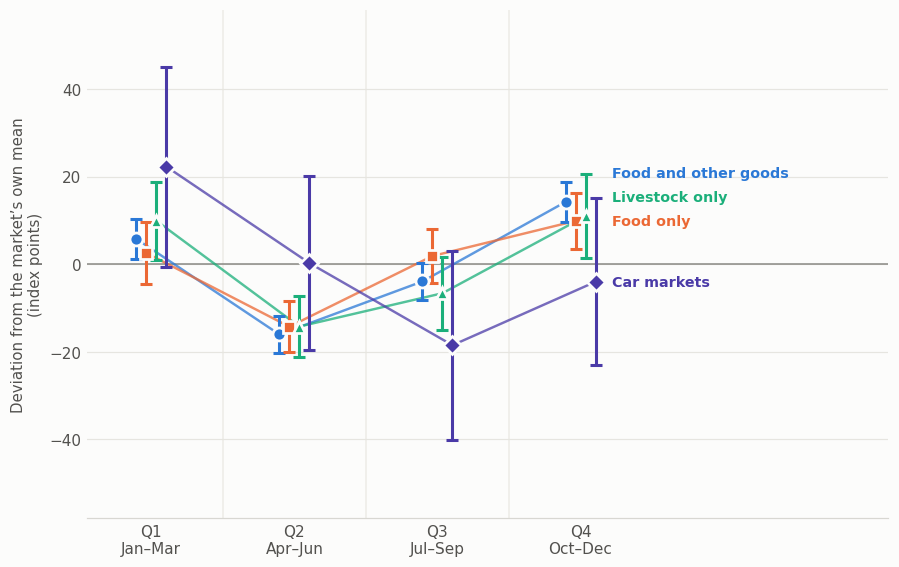

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E2.png


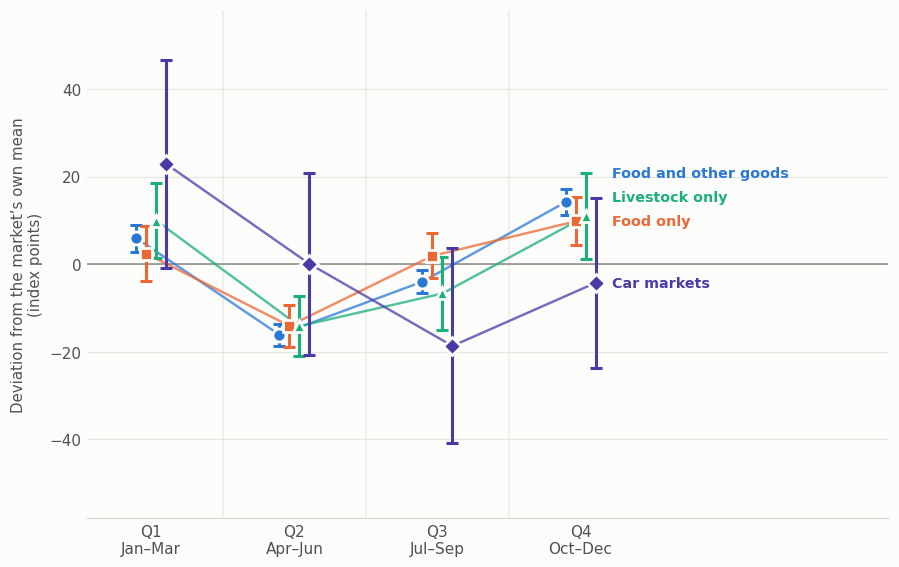

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E3.png
Sample by specification:


,markets,market-quarters
E,125,3628
E2,125,3848
E3,125,3848


Q4 - Q2 swing by goods group and specification (effect, SE, p):


E                    E2                     E3  \
                       swing     se      p   swing      se      p   swing   
Food and other goods  32.479  2.477  0.000  30.238   2.342  0.000  30.260   
Food only             25.952  3.420  0.000  24.137   4.247  0.000  23.847   
Livestock only        26.713  5.395  0.000  25.200   6.644  0.000  25.050   
Car markets            2.954  7.784  0.704  -4.261  16.380  0.795  -4.339   

                                     
                          se      p  
Food and other goods   2.369  0.000  
Food only              4.463  0.000  
Livestock only         7.275  0.001  
Car markets           17.248  0.801

In [343]:
# --- Specification E, secondary regressions: all market-years, robust standard errors ---
PE_Q_ALL = pe_build(full_years=False)
PE_SPECS = {   # name: (data, year and access controls, covariance, title, model note, SE note)
    "E": (PE_Q, True, "cluster", None, None, None),
    "E2": (PE_Q_ALL, True, "HC1", "E2.  All market-years, controlling for year and market access",
           "act ~ 0 + quarter × goods category + year + access, no constant. All market-years.\n"
           "Year and access enter additively, not interacted with quarter.", "robust (HC1)"),
    "E3": (PE_Q_ALL, False, "HC1", "E3.  All market-years, no controls",
           "act ~ 0 + quarter × goods category, no constant. All market-years.\n"
           "No year or access controls.", "robust (HC1)"),
}
PE_RES = {}
for name, (q, controls, cov, title, model, se_note) in PE_SPECS.items():
    m, B, SE, SW = pe_estimate(q, controls=controls, cov=cov)
    PE_RES[name] = dict(B=B, SE=SE, SW=SW, n_markets=q.Location.nunique(), n_obs=len(q))
    if name != "E":                                # E is drawn above
        pe_draw(B, SE, SW, q.Location.nunique(), len(q), os.path.join(OUT_SEAS, f"panel_{name}.png"),
                title=title, model=model, se_note=se_note)

print("Sample by specification:")
display(pd.DataFrame({n: {"markets": r["n_markets"], "market-quarters": r["n_obs"]} for n, r in PE_RES.items()}).T)
PE_SWINGS = pd.concat({n: pd.DataFrame(r["SW"], index=["swing", "se", "p"]).T for n, r in PE_RES.items()}, axis=1)
print("Q4 - Q2 swing by goods group and specification (effect, SE, p):")
display(PE_SWINGS.round(3))
PE_SWINGS.to_csv(os.path.join(OUT_SEAS, "panel_E_swings_by_specification.csv"))

**Specification E on a market-level quarterly index.** Same sample and clustered standard errors as
specification E. The outcome is each market-quarter's activity relative to that market-year's average:
100 x quarter mean / mean of the market-year's four quarterly means. Every market-year averages 100, so
differences in level between markets and between years drop out, and only the seasonal shape is left.
For the same reason the year and access dummies are exactly zero, so they are left out of this regression.

125 markets, 3,628 market-quarters, 2018-2025
Index distribution: {'count': 3628.0, 'mean': 100.0, 'std': 23.4, 'min': -5.7, '1%': 39.0, '50%': 100.2, '99%': 165.9, 'max': 217.4}

Cell levels (index):


,Q1,Q2,Q3,Q4
Food and other goods,105.16,85.23,96.58,113.02
Food only,101.76,88.53,100.48,109.23
Livestock only,110.39,88.20,92.53,108.88
Car markets,114.68,96.78,85.39,103.15


Q4 - Q2 swing (index points, SE, p):


,effect,se,p
Food and other goods,27.791,2.024,0.000
Food only,20.697,2.624,0.000
Livestock only,20.673,5.216,0.000
Car markets,6.365,7.574,0.401


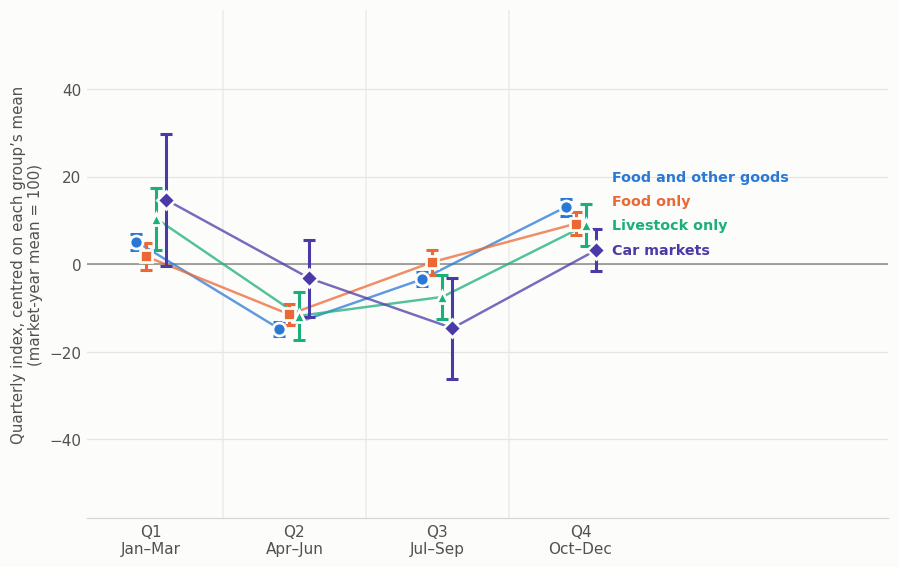

saved C:\Users\wb434633\WBG\Christina Wieser - Afghanistan\Geospatial information\MarketActivityIndex\output_paper\seasonality\panel_E_index.png


In [344]:
# --- Specification E on a market-level quarterly index (market-year mean = 100) -----------
PE_Q_IDX = pe_build(index=True)
# Every market-year averages 100, so year and access dummies are exactly zero here (and their clustered
# variances numerically singular): they are left out, which leaves the other coefficients unchanged.
PE_M_IDX, PE_B_IDX, PE_SE_IDX, PE_SW_IDX = pe_estimate(PE_Q_IDX, controls=False)
print(f"{PE_Q_IDX.Location.nunique()} markets, {len(PE_Q_IDX):,} market-quarters, 2018-2025")
print("Index distribution:", PE_Q_IDX.act.describe(percentiles=[.01, .5, .99]).round(1).to_dict())
print("\nCell levels (index):")
display(PE_B_IDX.round(2))
print("Q4 - Q2 swing (index points, SE, p):")
display(pd.DataFrame(PE_SW_IDX, index=["effect", "se", "p"]).T.round(3))
pe_draw(PE_B_IDX, PE_SE_IDX, PE_SW_IDX, PE_Q_IDX.Location.nunique(), len(PE_Q_IDX),
        os.path.join(OUT_SEAS, "panel_E_index.png"),
        title="E.  Market-level quarterly index",
        model="index ~ 0 + quarter × goods category, no constant; index = 100 × quarter / market-year mean.\n"
              "Year and access controls drop out: every market-year averages 100.",
        ylabel="Quarterly index, centred on each group’s mean\n(market-year mean = 100)")

**Market-level quarterly index by market access.** The same regression as the index figure above, with
the three access categories (high, intermediate, remote) as the groups of interest instead of goods:
`index ~ 0 + quarter x access category`, standard errors clustered by market, 90% confidence intervals.
Every market has an access category, so markets without goods information also enter. The last table tests
whether the Q4 - Q2 swing differs between access categories.

In [ ]:
# --- Market-level quarterly index by market access (market-year mean = 100) ---------------
PE_Q_ACC = pe_build(index=True, by="access")
PE_M_ACC, PE_B_ACC, PE_SE_ACC, PE_SW_ACC = pe_estimate(PE_Q_ACC, controls=False, order=PA_ORDER, sh=PA_SH)
print(f"{PE_Q_ACC.Location.nunique()} markets, {len(PE_Q_ACC):,} market-quarters, 2018-2025")
print("Markets by access category:", PE_Q_ACC.groupby("group").Location.nunique().reindex(PA_ORDER).to_dict())
print("\nCell levels (index):")
display(PE_B_ACC.round(2))
print("Q4 - Q2 swing (index points, SE, p):")
display(pd.DataFrame(PE_SW_ACC, index=["effect", "se", "p"]).T.round(3))

# Does the Q4 - Q2 swing differ between access categories?
_k = lambda g, j: f"C(cell)[{PA_SH[g]}_Q{j}]"
_rows = []
for g1, g2 in [("High access", "Intermediate access"), ("High access", "Remote"), ("Intermediate access", "Remote")]:
    t = PE_M_ACC.t_test(f"({_k(g1, 4)} - {_k(g1, 2)}) - ({_k(g2, 4)} - {_k(g2, 2)}) = 0")
    _rows.append({"comparison": f"{g1} - {g2}", "difference": float(t.effect[0]), "se": float(t.sd[0, 0]),
                  "p": float(t.pvalue)})
print("Difference in the Q4 - Q2 swing between access categories:")
display(pd.DataFrame(_rows).round(3))

pe_draw(PE_B_ACC, PE_SE_ACC, PE_SW_ACC, PE_Q_ACC.Location.nunique(), len(PE_Q_ACC),
        os.path.join(OUT_SEAS, "panel_E_index_access.png"),
        title="E.  Market-level quarterly index, by market access",
        model="index ~ 0 + quarter × access category, no constant; index = 100 × quarter / market-year mean.\n"
              "Year and access controls drop out: every market-year averages 100.",
        ylabel="Quarterly index, centred on each group’s mean\n(market-year mean = 100)",
        style=PA_STYLE)

market days: 137 markets; markets per year-month min 70, median 128; mean activity 99.5 (range 55.1 to 139.7)
non-market days: 137 markets; markets per year-month min 122, median 136; mean activity 1.4 (range -15.2 to 39.9)


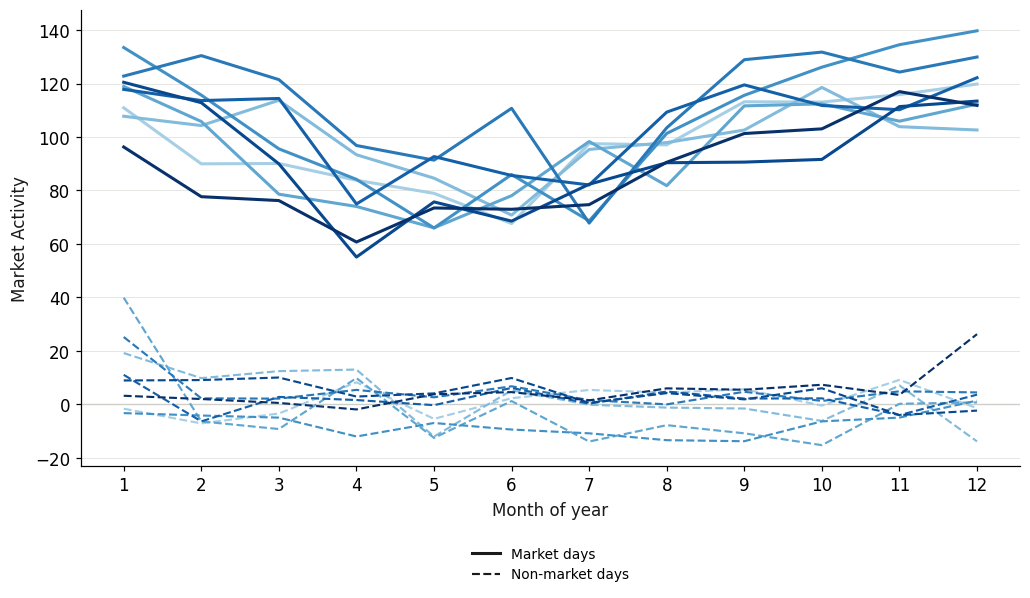

In [345]:
# --- Figure: monthly activity by year, market days and non-market days (all markets, 2018-2025) ---
SEAS_VAR = "activity_area_norm2020"
YEARS_M = list(range(2018, 2026))
DAY_TYPES = {1: "market days", 0: "non-market days"}
mm = df_act[df_act.mktDay.isin(DAY_TYPES) & df_act[SEAS_VAR].notna() & df_act.year.isin(YEARS_M)]
# one reading per market, day type and date (simple mean), then the mean per market and month
per_date = mm.groupby(["mktDay", "mktID", "date"])[SEAS_VAR].mean().reset_index()
per_date["year"], per_date["month"] = per_date.date.dt.year, per_date.date.dt.month
per_month = per_date.groupby(["mktDay", "mktID", "year", "month"])[SEAS_VAR].mean().reset_index()
MONTHLY = (per_month.groupby(["mktDay", "year", "month"])
           .agg(mean=(SEAS_VAR, "mean"), markets=("mktID", "nunique")).reset_index())
MONTHLY.insert(0, "day_type", MONTHLY.mktDay.map(DAY_TYPES))
MONTHLY.to_csv(os.path.join(OUT_SEAS, "monthly_market_day_activity_by_year.csv"), index=False)
for k, v in DAY_TYPES.items():
    s = MONTHLY[MONTHLY.mktDay == k]
    print(f"{v}: {per_month[per_month.mktDay == k].mktID.nunique()} markets; markets per year-month "
          f"min {s.markets.min()}, median {int(s.markets.median())}; mean activity {s['mean'].mean():.1f} "
          f"(range {s['mean'].min():.1f} to {s['mean'].max():.1f})")

colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(YEARS_M)))       # ordered years: light (2018) to dark (2025)
STYLE = {1: dict(ls="-", lw=2.0), 0: dict(ls="--", lw=1.4)}
fig, ax = plt.subplots(figsize=(9.5, 5.6))
for c, yr in zip(colors, YEARS_M):
    for k in DAY_TYPES:
        s = MONTHLY[(MONTHLY.year == yr) & (MONTHLY.mktDay == k)]
        ax.plot(s.month, s["mean"], color=c, zorder=3, label=str(yr) if k == 1 else None, **STYLE[k])
ax.axhline(0, color=RULE, lw=0.9, zorder=1)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month of year", color=INK)
ax.set_ylabel(f"Market Activity", color=INK)
# ax.set_title(f"Monthly activity by year, market and non-market days ({per_month.mktID.nunique()} markets, "
#              f"{YEARS_M[0]}\u2013{YEARS_M[-1]})", loc="left", fontsize=12, fontweight="bold", color=INK)
grid(ax)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
year_legend = ax.legend(title="Year", ncol=2, frameon=False, fontsize=9, title_fontsize=9,
                        loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.add_artist(year_legend)
style_handles = [plt.Line2D([], [], color=INK, label=DAY_TYPES[k].capitalize(), **STYLE[k]) for k in DAY_TYPES]
style_legend = ax.legend(handles=style_handles, frameon=False, fontsize=9, loc='upper center',
                          bbox_to_anchor=(0.5, -0.15))


fig.tight_layout()
f = os.path.join(OUT_SEAS, "monthly_market_day_activity_by_year.png")
fig.savefig(f, bbox_inches="tight", bbox_extra_artists=[year_legend, style_legend])
plt.show()





# # ... [Your data processing code remains the same] ...

# colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(YEARS_M)))  # ordered years: light (2018) to dark (2025)
# STYLE = {1: dict(ls="-", lw=2.0), 0: dict(ls="--", lw=1.4)}

# fig, ax = plt.subplots(figsize=(9.5, 5.6))

# for c, yr in zip(colors, YEARS_M):
#     for k in DAY_TYPES:
#         s = MONTHLY[(MONTHLY.year == yr) & (MONTHLY.mktDay == k)]
#         ax.plot(s.month, s['mean'], color=c, zorder=3, label=str(yr) if k == 1 else None, **STYLE[k])

# ax.axhline(0, color=RULE, lw=0.9, zorder=1)
# ax.set_xticks(range(1, 13))
# ax.set_xlabel("Month of year", color=INK)
# ax.set_ylabel(f"Mean {SEAS_VAR}", color=INK)
# ax.set_title(f"Monthly activity by year, market and non-market da") # Complete title if needed

# # --- UPDATED LEGEND SECTION ---
# # Places the legend centered horizontally (0.5) and just below the x-axis (-0.15)
# ax.legend(
#     loc='upper center', 
#     bbox_to_anchor=(0.5, -0.15), 
#     ncol=len(YEARS_M), 
#     frameon=False
# )

# # Ensures the legend fits inside the saved/displayed image canvas
# plt.tight_layout()
# plt.show()
# f = os.path.join(OUT_SEAS, "monthly_market_day_activity_by_year_updated_legend.png")
# plt.savefig(f, bbox_inches="tight")
# print("saved", f)
# print("saved", f)

**Summary: market activity across the year**

- **Sample for specification E:** 125 markets and 3,640 market-quarters.
  - By goods group (`category_label`): food and other goods 85, food only 29, livestock only 8, car markets 3.
  - Market-day readings below -5 are dropped (none is above 300).
  - Also left out: the 10 markets whose goods are not specified, the two markets not in the WFP list, and market-years without all four quarters.
  - Market lon62_5018lat34_2416 (Pashtonzarghon, Hirat; livestock only) enters on Monday, as in the rest of the paper.
- **Seasonal swing:** market-day activity is lowest in Q2 (Apr-Jun) and highest in Q4 (Oct-Dec), after controlling for year and access. The Q4 - Q2 swing is:
  - 32 index points for food and other goods (p < 0.001)
  - 26 for food only (p < 0.001)
  - 29 for livestock only (p < 0.001)
  - no swing for car markets (3.0, p = 0.70; only 3 markets)
- **Secondary regressions (all market-years, robust standard errors):** keeping incomplete years adds 211 market-quarters (3,851 in total, same 125 markets).
  - The swings change little: food and other goods 30.3 with controls (E2) and 30.3 without (E3), food only 24.1 and 23.8, livestock only 29.6 in both (all p < 0.001).
  - Car markets show no swing in either (-4.2 and -4.3, p = 0.80).
- **Market-level index (market-year mean = 100):** the same seasonal shape holds once each market-year's level is removed.
  - Food and other goods are about 15% below their market-year average in Q2 and 13% above it in Q4, a swing of 28 index points.
  - The swing is 21 points for food only and 23 for livestock only (all p < 0.001).
  - Car markets show no significant swing (6.4, p = 0.40).
- **Market-level index by market access:** all 137 markets (4,004 market-quarters). The seasonal shape is the same in every access category: the Q4 - Q2 swing is 26.4 index points for high-access markets, 23.2 for intermediate and 25.7 for remote (all p < 0.001), and none of the pairwise differences is significant (p = 0.36, 0.84 and 0.45).
- **Monthly profile:** the pattern repeats every year from 2018 to 2025. Activity falls from January to a low in April-July (about 56-76) and rises to a high in October-January (about 117-141).
- **Recent years:** 2024 and 2025 have the deepest spring lows (56 and 61 in April) and lower first-half levels than 2018-2023. Their autumn peaks are among the lowest of the period.
- **Non-market days (dashed lines):** activity stays close to zero all year (mean 1.2). Most months are within about ±15, with a few January and December spikes (up to 39). The seasonal swing is therefore specific to market days; it is not a background change in the whole area.
- **Coverage:** all 137 markets. Between 69 and 137 markets contribute to each year-month on market days (median 128), and between 122 and 137 on non-market days (median 136). The monthly figure does not apply the -5 to 300 filter.